# TRUST-MANET — complete pipeline (Kaggle / Colab / local Linux)

One self-contained notebook, start to end: it writes every source file, builds ns-3,
generates the dataset, trains the detector, runs the collusion-robust trust mechanism,
and displays all results and figures inline.

**Where it runs:** Kaggle (turn Internet ON), Colab (mounts Drive), or local Linux/macOS
(ns-3 does not build on native Windows — use WSL2 Ubuntu). Run cells top to bottom; the
first run builds ns-3 (~10-20 min).

## 1. Environment + paths (auto-detected)

In [1]:
import os, sys
ON_KAGGLE = os.path.isdir('/kaggle')
ON_COLAB  = ('google.colab' in sys.modules) or (os.path.isdir('/content') and not ON_KAGGLE)
if ON_KAGGLE:
    ENV='kaggle'; CODE_DIR='/kaggle/working/trust-manet-dataset'; NS3_DIR='/kaggle/temp/ns-3-dev'
    RAW_DIR='/kaggle/temp/raw'; DS_DIR='/kaggle/working/dataset'; SPLIT_DIR='/kaggle/working/dataset_split'; OUT='/kaggle/working'
elif ON_COLAB:
    ENV='colab'; from google.colab import drive; drive.mount('/content/drive')
    PROJECT='/content/drive/MyDrive/trust-manet'; CODE_DIR='/content/trust-manet-dataset'; NS3_DIR='/content/ns-3-dev'
    RAW_DIR=f'{PROJECT}/raw'; DS_DIR=f'{PROJECT}/dataset'; SPLIT_DIR=f'{PROJECT}/dataset_split'; OUT=PROJECT
else:
    ENV='local'; BASE=os.path.abspath('trust-manet-work')
    CODE_DIR=f'{BASE}/code'; NS3_DIR=f'{BASE}/ns-3-dev'; RAW_DIR=f'{BASE}/raw'
    DS_DIR=f'{BASE}/dataset'; SPLIT_DIR=f'{BASE}/dataset_split'; OUT=BASE
for dd in (CODE_DIR,RAW_DIR,DS_DIR,SPLIT_DIR,OUT,f'{CODE_DIR}/ns3',f'{CODE_DIR}/scripts'):
    os.makedirs(dd, exist_ok=True)
os.chdir(CODE_DIR)
print('environment:',ENV,'| code:',CODE_DIR,'| ns-3:',NS3_DIR,'| outputs:',OUT)


environment: kaggle | code: /kaggle/working/trust-manet-dataset | ns-3: /kaggle/temp/ns-3-dev | outputs: /kaggle/working


## 2. Prerequisites (build tools + Python deps)

In [2]:
import shutil, subprocess, sys
need=[t for t in ('git','g++','cmake','make') if shutil.which(t) is None]
if need:
    print('Missing build tools:', need)
    if ENV in ('kaggle','colab'):
        subprocess.run('apt-get -qq update', shell=True)
        subprocess.run('apt-get -qq install -y git g++ cmake make python3', shell=True)
    else:
        print('LOCAL: sudo apt-get install -y git g++ cmake make python3   (macOS: xcode-select --install; brew install cmake)')
else:
    print('build tools present')
subprocess.run([sys.executable,'-m','pip','install','-q','pandas','numpy','pyarrow','pyyaml','lightgbm','scikit-learn','matplotlib'])
print(subprocess.run(['g++','--version'],capture_output=True,text=True).stdout.splitlines()[0] if shutil.which('g++') else 'g++ NOT found')


build tools present
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


## 3. Write all source files

In [3]:
%%writefile ns3/malicious-routing.h
/*
 * TRUST-MANET : malicious-routing.h
 * ---------------------------------
 * A thin subclass of ns3::aodv::RoutingProtocol that injects forwarding
 * misbehaviour for a selected set of "compromised" nodes:
 *
 *   BLACKHOLE  -> drop ALL transit (forwarded) application data packets.
 *   GRAYHOLE   -> drop transit application data packets with probability p.
 *   NONE       -> behave exactly like stock AODV (benign node).
 *
 * Only the *data-forwarding* path is altered. All AODV control logic
 * (RREQ/RREP/RERR, route table, local delivery) is inherited unchanged,
 * so routing still converges and the misbehaviour is observable purely as
 * a forwarding anomaly -- which is exactly the signal the local IDS in the
 * TRUST-MANET proposal is meant to detect, separated from mobility loss.
 *
 * NOTE on attack *attraction*: a full blackhole also spoofs RREPs (high dst
 * seqno, hop-count 1) to attract traffic. That requires editing AODV's
 * RecvRequest/SendReply and is version-specific. This file deliberately
 * implements the lower-risk, version-stable *drop* behaviour only. See
 * README.md "Optional: RREP-spoofing attraction" for how to add it.
 *
 * Targeted ns-3 version: ns-3.42 (public Ipv4RoutingProtocol / aodv API).
 */
#ifndef TRUST_MANET_MALICIOUS_ROUTING_H
#define TRUST_MANET_MALICIOUS_ROUTING_H

#include "ns3/aodv-routing-protocol.h"
#include "ns3/random-variable-stream.h"
#include "ns3/nstime.h"
#include "ns3/ipv4-header.h"
#include "ns3/ipv4-route.h"

namespace ns3
{

class MaliciousRouting : public aodv::RoutingProtocol
{
  public:
    enum AttackType
    {
        NONE = 0,
        BLACKHOLE = 1,
        GRAYHOLE = 2
    };

    static TypeId GetTypeId();
    MaliciousRouting();
    ~MaliciousRouting() override;

    /** Configure this node as an attacker. dropProb only used for GRAYHOLE. */
    void SetAttack(AttackType type, double dropProb, Time start, Time stop);

    /** Overridden forwarding decision. */
    bool RouteInput(Ptr<const Packet> p,
                    const Ipv4Header& header,
                    Ptr<const NetDevice> idev,
                    const UnicastForwardCallback& ucb,
                    const MulticastForwardCallback& mcb,
                    const LocalDeliverCallback& lcb,
                    const ErrorCallback& ecb) override;

    // --- cumulative counters, read (as deltas) once per measurement window ---
    uint64_t m_recvForward = 0;   // transit data packets that reached the forwarding hook
    uint64_t m_fwdOk = 0;         // transit data packets actually forwarded
    uint64_t m_fwdDropAttack = 0; // transit data packets dropped by the attack
    uint64_t m_noRoute = 0;       // ErrorCallback invocations (no route / route break)

    AttackType GetAttackType() const { return m_attack; }

  private:
    // Static hooks are bound (via MakeBoundCallback) with `this` + the original
    // callback, so they match the exact ns-3 callback signatures.
    static void ForwardHook(MaliciousRouting* self,
                            UnicastForwardCallback ucb,
                            Ptr<Ipv4Route> route,
                            Ptr<const Packet> p,
                            const Ipv4Header& header);

    static void ErrorHook(MaliciousRouting* self,
                          ErrorCallback ecb,
                          Ptr<const Packet> p,
                          const Ipv4Header& header,
                          Socket::SocketErrno err);

    bool AttackActiveNow() const;

    AttackType m_attack = NONE;
    double m_dropProb = 0.0;
    Time m_start = Seconds(0);
    Time m_stop = Seconds(0);
    Ptr<UniformRandomVariable> m_rng;
};

} // namespace ns3

#endif // TRUST_MANET_MALICIOUS_ROUTING_H


Writing ns3/malicious-routing.h


In [4]:
%%writefile ns3/malicious-routing.cc
/*
 * TRUST-MANET : malicious-routing.cc
 * See malicious-routing.h for the design rationale.
 */
#include "malicious-routing.h"

#include "ns3/log.h"
#include "ns3/simulator.h"

namespace ns3
{

NS_LOG_COMPONENT_DEFINE("MaliciousRouting");
NS_OBJECT_ENSURE_REGISTERED(MaliciousRouting);

TypeId
MaliciousRouting::GetTypeId()
{
    static TypeId tid = TypeId("ns3::MaliciousRouting")
                            .SetParent<aodv::RoutingProtocol>()
                            .SetGroupName("Internet")
                            .AddConstructor<MaliciousRouting>();
    return tid;
}

MaliciousRouting::MaliciousRouting()
{
    // UniformRandomVariable already defaults to the [0, 1) range we need,
    // so there is no need to set Min/Max (which would require ns3/double.h).
    m_rng = CreateObject<UniformRandomVariable>();
}

MaliciousRouting::~MaliciousRouting()
{
}

void
MaliciousRouting::SetAttack(AttackType type, double dropProb, Time start, Time stop)
{
    m_attack = type;
    m_dropProb = dropProb;
    m_start = start;
    m_stop = stop;
}

bool
MaliciousRouting::AttackActiveNow() const
{
    if (m_attack == NONE)
    {
        return false;
    }
    Time now = Simulator::Now();
    return (now >= m_start) && (now < m_stop);
}

void
MaliciousRouting::ForwardHook(MaliciousRouting* self,
                              UnicastForwardCallback ucb,
                              Ptr<Ipv4Route> route,
                              Ptr<const Packet> p,
                              const Ipv4Header& header)
{
    // Only *transit* (forwarded) packets reach a UnicastForwardCallback;
    // locally-delivered packets go through the LocalDeliverCallback and are
    // never affected here.
    self->m_recvForward++;

    // Protocol 17 == UDP. Application data in this framework is UDP CBR;
    // AODV control is sent over AODV's own sockets and is not forwarded via
    // this transit path, so "transit UDP" == application data.
    const bool isData = (header.GetProtocol() == 17);

    if (isData && self->AttackActiveNow())
    {
        bool drop = false;
        if (self->m_attack == BLACKHOLE)
        {
            drop = true;
        }
        else if (self->m_attack == GRAYHOLE)
        {
            drop = (self->m_rng->GetValue() < self->m_dropProb);
        }

        if (drop)
        {
            self->m_fwdDropAttack++;
            // Silently drop: do NOT invoke ucb -> packet is not forwarded.
            return;
        }
    }

    self->m_fwdOk++;
    ucb(route, p, header);
}

void
MaliciousRouting::ErrorHook(MaliciousRouting* self,
                            ErrorCallback ecb,
                            Ptr<const Packet> p,
                            const Ipv4Header& header,
                            Socket::SocketErrno err)
{
    // Invoked by AODV when a transit packet cannot be routed (no route /
    // broken route). Counted for every node (benign + malicious) so the
    // feature pipeline can separate "malicious drop" from "no-route drop".
    self->m_noRoute++;
    ecb(p, header, err);
}

bool
MaliciousRouting::RouteInput(Ptr<const Packet> p,
                             const Ipv4Header& header,
                             Ptr<const NetDevice> idev,
                             const UnicastForwardCallback& ucb,
                             const MulticastForwardCallback& mcb,
                             const LocalDeliverCallback& lcb,
                             const ErrorCallback& ecb)
{
    // Wrap both the unicast-forward and error callbacks so our counters fire
    // whether forwarding happens synchronously or after AODV finishes a
    // route discovery. Local delivery (lcb) and multicast (mcb) are passed
    // through untouched.
    UnicastForwardCallback wrappedUcb = MakeBoundCallback(&MaliciousRouting::ForwardHook, this, ucb);
    ErrorCallback wrappedEcb = MakeBoundCallback(&MaliciousRouting::ErrorHook, this, ecb);

    return aodv::RoutingProtocol::RouteInput(p, header, idev, wrappedUcb, mcb, lcb, wrappedEcb);
}

} // namespace ns3


Writing ns3/malicious-routing.cc


In [5]:
%%writefile ns3/trust-manet-sim.cc
/*
 * TRUST-MANET : trust-manet-sim.cc
 * --------------------------------
 * One parameterised ns-3 run of an AODV MANET under a chosen attack mode.
 * Produces three files per run:
 *
 *   <prefix>_nodes.csv : per-window, per-node measurements (deltas within the window)
 *   <prefix>_edges.csv : per-window 1-hop adjacency (node pairs within rangeM)
 *   <prefix>_meta.json : the run configuration + ground-truth malicious node IDs
 *
 * The Python pipeline (scripts/build_dataset.py) turns these into the
 * per-(observer, neighbour, window) Parquet dataset described in the proposal.
 *
 * Install: copy this file + malicious-routing.{h,cc} into
 *          <ns3>/scratch/trust-manet/  and build with
 *          ./ns3 build trust-manet
 *
 * Targeted ns-3 version: ns-3.42.
 */
#include "malicious-routing.h"

#include "ns3/applications-module.h"
#include "ns3/core-module.h"
#include "ns3/internet-module.h"
#include "ns3/mobility-module.h"
#include "ns3/network-module.h"
#include "ns3/wifi-module.h"

#include <algorithm>
#include <cmath>
#include <fstream>
#include <numeric>
#include <random>
#include <sstream>
#include <string>
#include <vector>

using namespace ns3;

NS_LOG_COMPONENT_DEFINE("TrustManetSim");

// ---------------------------------------------------------------------------
// Routing helper that installs MaliciousRouting (an AODV subclass) on every
// node. Maliciousness is switched on afterwards per selected node.
// ---------------------------------------------------------------------------
class MaliciousAodvHelper : public Ipv4RoutingHelper
{
  public:
    MaliciousAodvHelper() { m_factory.SetTypeId("ns3::MaliciousRouting"); }

    MaliciousAodvHelper* Copy() const override { return new MaliciousAodvHelper(*this); }

    Ptr<Ipv4RoutingProtocol> Create(Ptr<Node> node) const override
    {
        Ptr<MaliciousRouting> agent = m_factory.Create<MaliciousRouting>();
        node->AggregateObject(agent);
        return agent;
    }

  private:
    ObjectFactory m_factory;
};

// ---------------------------------------------------------------------------
// Application traffic counters (indexed by node id).
// ---------------------------------------------------------------------------
static void
TxSink(std::vector<uint64_t>* v, uint32_t node, Ptr<const Packet>)
{
    (*v)[node]++;
}

static void
RxSink(std::vector<uint64_t>* v, uint32_t node, Ptr<const Packet>, const Address&)
{
    (*v)[node]++;
}

// ---------------------------------------------------------------------------
// Per-window collector.
// ---------------------------------------------------------------------------
struct Collector
{
    NodeContainer nodes;
    uint32_t nNodes = 0;
    double windowSec = 5.0;
    double rangeM = 120.0;
    double simStop = 200.0;

    std::ofstream nodesOut;
    std::ofstream edgesOut;

    std::vector<uint64_t> pRecv, pOk, pDrop, pNoRoute, pTx, pRx; // previous cumulative
    std::vector<uint64_t>* appTx = nullptr;
    std::vector<uint64_t>* appRx = nullptr;

    uint32_t widx = 0;

    void Start()
    {
        pRecv.assign(nNodes, 0);
        pOk.assign(nNodes, 0);
        pDrop.assign(nNodes, 0);
        pNoRoute.assign(nNodes, 0);
        pTx.assign(nNodes, 0);
        pRx.assign(nNodes, 0);

        nodesOut << "window_idx,time_s,node,pos_x,pos_y,vel_x,vel_y,speed,"
                    "recv_forward,fwd_ok,fwd_drop_attack,no_route,app_tx,app_rx\n";
        edgesOut << "window_idx,i,j,dist\n";

        Simulator::Schedule(Seconds(windowSec), &Collector::Sample, this);
    }

    void Sample()
    {
        const double t = Simulator::Now().GetSeconds();
        std::vector<Vector> pos(nNodes);

        for (uint32_t n = 0; n < nNodes; ++n)
        {
            Ptr<Node> node = nodes.Get(n);
            Ptr<MobilityModel> mm = node->GetObject<MobilityModel>();
            Vector p = mm->GetPosition();
            Vector v = mm->GetVelocity();
            pos[n] = p;

            Ptr<MaliciousRouting> r = node->GetObject<MaliciousRouting>();

            const uint64_t recv = r->m_recvForward;
            const uint64_t ok = r->m_fwdOk;
            const uint64_t drop = r->m_fwdDropAttack;
            const uint64_t nr = r->m_noRoute;
            const uint64_t tx = (*appTx)[n];
            const uint64_t rx = (*appRx)[n];

            const uint64_t dRecv = recv - pRecv[n];
            const uint64_t dOk = ok - pOk[n];
            const uint64_t dDrop = drop - pDrop[n];
            const uint64_t dNr = nr - pNoRoute[n];
            const uint64_t dTx = tx - pTx[n];
            const uint64_t dRx = rx - pRx[n];

            const double speed = std::sqrt(v.x * v.x + v.y * v.y + v.z * v.z);

            nodesOut << widx << ',' << t << ',' << n << ',' << p.x << ',' << p.y << ',' << v.x
                     << ',' << v.y << ',' << speed << ',' << dRecv << ',' << dOk << ',' << dDrop
                     << ',' << dNr << ',' << dTx << ',' << dRx << '\n';

            pRecv[n] = recv;
            pOk[n] = ok;
            pDrop[n] = drop;
            pNoRoute[n] = nr;
            pTx[n] = tx;
            pRx[n] = rx;
        }

        // 1-hop adjacency within observation range.
        for (uint32_t i = 0; i < nNodes; ++i)
        {
            for (uint32_t j = i + 1; j < nNodes; ++j)
            {
                const double d = CalculateDistance(pos[i], pos[j]);
                if (d <= rangeM)
                {
                    edgesOut << widx << ',' << i << ',' << j << ',' << d << '\n';
                }
            }
        }

        widx++;
        if (Simulator::Now().GetSeconds() + windowSec <= simStop + 1e-9)
        {
            Simulator::Schedule(Seconds(windowSec), &Collector::Sample, this);
        }
    }
};

// ---------------------------------------------------------------------------
int
main(int argc, char* argv[])
{
    // ---- parameters ----
    uint32_t nNodes = 50;
    double speed = 5.0;             // m/s (0 => static)
    double compromisedFrac = 0.10;  // fraction of nodes that are attackers
    std::string attackType = "blackhole"; // clean | blackhole | grayhole
    double grayholeDropProb = 0.5;
    uint32_t nFlows = 15;
    double simTime = 200.0;
    double windowSec = 5.0;
    double attackStart = 20.0;
    double appStart = 2.0;
    double areaX = 1500.0;
    double areaY = 1500.0;
    double rangeM = 120.0;
    uint32_t seed = 1;
    std::string outPrefix = "run";

    CommandLine cmd(__FILE__);
    cmd.AddValue("nNodes", "Number of nodes", nNodes);
    cmd.AddValue("speed", "Max node speed in m/s (0 = static)", speed);
    cmd.AddValue("compromisedFrac", "Fraction of compromised nodes", compromisedFrac);
    cmd.AddValue("attackType", "clean | blackhole | grayhole", attackType);
    cmd.AddValue("grayholeDropProb", "Drop probability for grayhole", grayholeDropProb);
    cmd.AddValue("nFlows", "Number of CBR UDP flows", nFlows);
    cmd.AddValue("simTime", "Simulation time (s)", simTime);
    cmd.AddValue("windowSec", "Measurement window (s)", windowSec);
    cmd.AddValue("attackStart", "Attack start time (s)", attackStart);
    cmd.AddValue("appStart", "Application start time (s)", appStart);
    cmd.AddValue("areaX", "Area width (m)", areaX);
    cmd.AddValue("areaY", "Area height (m)", areaY);
    cmd.AddValue("rangeM", "Observation/adjacency range (m)", rangeM);
    cmd.AddValue("seed", "RNG run (also seeds node/flow selection)", seed);
    cmd.AddValue("outPrefix", "Output file prefix", outPrefix);
    cmd.Parse(argc, argv);

    SeedManager::SetSeed(1);
    SeedManager::SetRun(seed);

    // Deterministic (seed-controlled) selection independent of ns-3 streams.
    std::mt19937 gen(static_cast<uint32_t>(seed) * 2654435761u + 12345u);

    NodeContainer nodes;
    nodes.Create(nNodes);

    // ---- Wi-Fi (802.11b ad hoc) ----
    WifiHelper wifi;
    wifi.SetStandard(WIFI_STANDARD_80211b);
    wifi.SetRemoteStationManager("ns3::ConstantRateWifiManager",
                                 "DataMode",
                                 StringValue("DsssRate11Mbps"),
                                 "ControlMode",
                                 StringValue("DsssRate1Mbps"));

    YansWifiChannelHelper channel = YansWifiChannelHelper::Default();
    YansWifiPhyHelper phy;
    phy.SetChannel(channel.Create());

    WifiMacHelper mac;
    mac.SetType("ns3::AdhocWifiMac");

    NetDeviceContainer devices = wifi.Install(phy, mac, nodes);

    // ---- mobility ----
    MobilityHelper mob;
    Ptr<RandomRectanglePositionAllocator> posAlloc =
        CreateObject<RandomRectanglePositionAllocator>();
    {
        std::ostringstream sx, sy;
        sx << "ns3::UniformRandomVariable[Min=0|Max=" << areaX << "]";
        sy << "ns3::UniformRandomVariable[Min=0|Max=" << areaY << "]";
        posAlloc->SetAttribute("X", StringValue(sx.str()));
        posAlloc->SetAttribute("Y", StringValue(sy.str()));
    }
    mob.SetPositionAllocator(posAlloc);

    if (speed <= 0.0)
    {
        mob.SetMobilityModel("ns3::ConstantPositionMobilityModel");
    }
    else
    {
        std::ostringstream sp;
        sp << "ns3::ConstantRandomVariable[Constant=" << speed << "]";
        mob.SetMobilityModel("ns3::RandomWaypointMobilityModel",
                             "Speed",
                             StringValue(sp.str()),
                             "Pause",
                             StringValue("ns3::ConstantRandomVariable[Constant=0.0]"),
                             "PositionAllocator",
                             PointerValue(posAlloc));
    }
    mob.Install(nodes);

    // ---- internet stack with malicious-capable AODV ----
    MaliciousAodvHelper malHelper;
    InternetStackHelper internet;
    internet.SetRoutingHelper(malHelper);
    internet.Install(nodes);

    Ipv4AddressHelper address;
    address.SetBase("10.1.0.0", "255.255.0.0"); // /16 supports up to ~65k hosts
    Ipv4InterfaceContainer ifaces = address.Assign(devices);

    // ---- choose malicious nodes ----
    std::vector<uint32_t> idx(nNodes);
    std::iota(idx.begin(), idx.end(), 0);
    std::shuffle(idx.begin(), idx.end(), gen);

    uint32_t nMal = 0;
    MaliciousRouting::AttackType atk = MaliciousRouting::NONE;
    if (attackType == "blackhole")
    {
        atk = MaliciousRouting::BLACKHOLE;
    }
    else if (attackType == "grayhole")
    {
        atk = MaliciousRouting::GRAYHOLE;
    }
    else
    {
        atk = MaliciousRouting::NONE; // "clean"
    }

    if (atk != MaliciousRouting::NONE)
    {
        nMal = static_cast<uint32_t>(std::floor(compromisedFrac * nNodes));
    }

    std::vector<uint32_t> malicious(idx.begin(), idx.begin() + nMal);
    std::sort(malicious.begin(), malicious.end());

    for (uint32_t m : malicious)
    {
        Ptr<MaliciousRouting> r = nodes.Get(m)->GetObject<MaliciousRouting>();
        r->SetAttack(atk, grayholeDropProb, Seconds(attackStart), Seconds(simTime));
    }

    // ---- traffic: nFlows random source->destination CBR UDP flows ----
    std::vector<uint64_t> appTx(nNodes, 0), appRx(nNodes, 0);
    std::uniform_int_distribution<uint32_t> pick(0, nNodes - 1);

    for (uint32_t f = 0; f < nFlows; ++f)
    {
        uint32_t src = pick(gen);
        uint32_t dst = pick(gen);
        while (dst == src)
        {
            dst = pick(gen);
        }
        uint16_t port = static_cast<uint16_t>(9000 + f);

        OnOffHelper onoff("ns3::UdpSocketFactory",
                          InetSocketAddress(ifaces.GetAddress(dst), port));
        onoff.SetAttribute("DataRate", StringValue("16kbps"));
        onoff.SetAttribute("PacketSize", UintegerValue(512));
        onoff.SetAttribute("OnTime", StringValue("ns3::ConstantRandomVariable[Constant=1]"));
        onoff.SetAttribute("OffTime", StringValue("ns3::ConstantRandomVariable[Constant=0]"));
        ApplicationContainer srcApp = onoff.Install(nodes.Get(src));
        srcApp.Start(Seconds(appStart));
        srcApp.Stop(Seconds(simTime - 1.0));

        PacketSinkHelper sink("ns3::UdpSocketFactory",
                              InetSocketAddress(Ipv4Address::GetAny(), port));
        ApplicationContainer sinkApp = sink.Install(nodes.Get(dst));
        sinkApp.Start(Seconds(1.0));
        sinkApp.Stop(Seconds(simTime));

        srcApp.Get(0)->TraceConnectWithoutContext("Tx", MakeBoundCallback(&TxSink, &appTx, src));
        sinkApp.Get(0)->TraceConnectWithoutContext("Rx", MakeBoundCallback(&RxSink, &appRx, dst));
    }

    // ---- collector ----
    Collector col;
    col.nodes = nodes;
    col.nNodes = nNodes;
    col.windowSec = windowSec;
    col.rangeM = rangeM;
    col.simStop = simTime;
    col.appTx = &appTx;
    col.appRx = &appRx;
    col.nodesOut.open(outPrefix + "_nodes.csv");
    col.edgesOut.open(outPrefix + "_edges.csv");
    col.Start();

    // ---- meta ----
    {
        std::ofstream meta(outPrefix + "_meta.json");
        meta << "{\n";
        meta << "  \"n_nodes\": " << nNodes << ",\n";
        meta << "  \"speed\": " << speed << ",\n";
        meta << "  \"compromised_frac\": " << compromisedFrac << ",\n";
        meta << "  \"attack_type\": \"" << attackType << "\",\n";
        meta << "  \"grayhole_drop_prob\": " << grayholeDropProb << ",\n";
        meta << "  \"n_flows\": " << nFlows << ",\n";
        meta << "  \"sim_time\": " << simTime << ",\n";
        meta << "  \"window_sec\": " << windowSec << ",\n";
        meta << "  \"attack_start\": " << attackStart << ",\n";
        meta << "  \"app_start\": " << appStart << ",\n";
        meta << "  \"area_x\": " << areaX << ",\n";
        meta << "  \"area_y\": " << areaY << ",\n";
        meta << "  \"range_m\": " << rangeM << ",\n";
        meta << "  \"seed\": " << seed << ",\n";
        meta << "  \"malicious_nodes\": [";
        for (size_t k = 0; k < malicious.size(); ++k)
        {
            meta << malicious[k] << (k + 1 < malicious.size() ? ", " : "");
        }
        meta << "]\n}\n";
    }

    Simulator::Stop(Seconds(simTime));
    Simulator::Run();
    Simulator::Destroy();

    col.nodesOut.close();
    col.edgesOut.close();
    return 0;
}


Writing ns3/trust-manet-sim.cc


In [6]:
%%writefile scripts/build_ns3.sh
#!/usr/bin/env bash
# ---------------------------------------------------------------------------
# build_ns3.sh : fetch a pinned ns-3, install the TRUST-MANET scratch program,
#                and build only the modules we need (fast even on 1 core).
#
# Usage:
#   bash scripts/build_ns3.sh [NS3_DIR] [NS3_VERSION]
#
#   NS3_DIR      where to clone ns-3   (default: ./ns-3-dev)
#   NS3_VERSION  git tag to check out  (default: ns-3.42)
#
# After this finishes, run the matrix with scripts/run_matrix.py.
# ---------------------------------------------------------------------------
set -euo pipefail

NS3_DIR="${1:-$(pwd)/ns-3-dev}"
NS3_VERSION="${2:-ns-3.42}"
REPO="https://github.com/nsnam/ns-3-dev-git.git"

HERE="$(cd "$(dirname "${BASH_SOURCE[0]}")/.." && pwd)"   # project root

echo "==> Checking build prerequisites"
missing=()
for t in git g++ cmake python3 make; do
  command -v "$t" >/dev/null 2>&1 || missing+=("$t")
done
if [ "${#missing[@]}" -gt 0 ]; then
  echo "ERROR: missing tools: ${missing[*]}"
  echo "On Ubuntu/Debian:  sudo apt-get update && sudo apt-get install -y git g++ cmake python3 make"
  exit 1
fi

# Clone when there's no real git checkout yet. Checking for .git (not just the
# directory) means a pre-created empty dir or a half-finished clone won't block it.
if [ ! -d "$NS3_DIR/.git" ]; then
  echo "==> Cloning ns-3 ($NS3_VERSION) into $NS3_DIR"
  rm -rf "$NS3_DIR"
  git clone "$REPO" "$NS3_DIR"
fi

cd "$NS3_DIR"
echo "==> Checking out $NS3_VERSION"
git fetch --tags --quiet || true
git checkout "$NS3_VERSION"

echo "==> Installing TRUST-MANET scratch program"
mkdir -p scratch/trust-manet
# Name the main file after the directory so the run target is simply 'trust-manet'.
cp "$HERE/ns3/trust-manet-sim.cc"   scratch/trust-manet/trust-manet.cc
cp "$HERE/ns3/malicious-routing.cc" scratch/trust-manet/
cp "$HERE/ns3/malicious-routing.h"  scratch/trust-manet/
rm -f scratch/trust-manet/trust-manet-sim.cc   # drop any stale duplicate main

echo "==> Configuring (optimized, minimal module set)"
# NOTE: ns-3 expects a SEMICOLON-separated, quoted module list; dependencies are
# resolved automatically. Limiting modules cuts build time/memory. Add modules
# here if you extend the simulation (e.g. flow-monitor, energy).
./ns3 clean || true
./ns3 configure -d optimized \
  --enable-modules='core;network;internet;wifi;mobility;aodv;applications;propagation' \
  --disable-examples --disable-tests

echo "==> Building"
# Builds the enabled libraries + the scratch program. (Building by explicit
# target name is avoided because the short name is not accepted on every version.)
./ns3 build

echo
echo "==> Done. ns-3 is at: $NS3_DIR"
echo "    Smoke test:"
echo "    (cd \"$NS3_DIR\" && ./ns3 run \"trust-manet --nNodes=25 --attackType=blackhole --simTime=60 --outPrefix=/tmp/smoke\")"


Writing scripts/build_ns3.sh


In [7]:
%%writefile scripts/run_matrix.py
#!/usr/bin/env python3
"""
run_matrix.py
-------------
Enumerate the TRUST-MANET scenario matrix and run the compiled ns-3 program
once per (sim-factor combination x seed). Raw outputs (<run_id>_nodes.csv,
<run_id>_edges.csv, <run_id>_meta.json) are written into --out.

Prereq: build the simulator first with scripts/build_ns3.sh.

Examples
--------
# fast screening pass (36 runs) to validate the pipeline:
python scripts/run_matrix.py --ns3-dir ./ns-3-dev --which screening --out raw/

# full matrix (450 runs) -- long; use --resume to restart safely:
python scripts/run_matrix.py --ns3-dir ./ns-3-dev --which full --out raw/ --resume
"""
import argparse
import math
import os
import subprocess
import sys
import csv

try:
    import yaml
except ImportError:
    sys.exit("PyYAML missing. Run: pip install -r requirements.txt")


def enumerate_runs(cfg, which):
    m = cfg[which]
    fixed = cfg["fixed"]
    runs = []
    for n in m["sim_factors"]["n_nodes"]:
        for speed in m["sim_factors"]["speed"]:
            for atk in m["sim_factors"]["attack"]:
                for seed in m["seeds"]:
                    attack_type = atk["attack_type"]
                    cfrac = float(atk["compromised_frac"])
                    scenario_id = f"n{n}_s{speed}_{attack_type}_c{cfrac:.2f}"
                    run_id = f"{scenario_id}_seed{seed}"
                    # derived
                    area = n * float(fixed["density_m2_per_node"])
                    side = round(math.sqrt(area), 1)
                    n_flows = max(1, round(fixed["n_flows_per_25_nodes"] * n / 25.0))
                    runs.append(
                        dict(
                            run_id=run_id,
                            scenario_id=scenario_id,
                            n_nodes=n,
                            speed=speed,
                            attack_type=attack_type,
                            compromised_frac=cfrac,
                            seed=seed,
                            area_x=side,
                            area_y=side,
                            n_flows=n_flows,
                        )
                    )
    return runs, fixed


def build_cmd(run, fixed, out_dir):
    prefix = os.path.join(os.path.abspath(out_dir), run["run_id"])
    args = [
        f"--nNodes={run['n_nodes']}",
        f"--speed={run['speed']}",
        f"--attackType={run['attack_type']}",
        f"--compromisedFrac={run['compromised_frac']}",
        f"--grayholeDropProb={fixed['grayhole_drop_prob']}",
        f"--nFlows={run['n_flows']}",
        f"--simTime={fixed['sim_time']}",
        f"--windowSec={fixed['window_sec']}",
        f"--attackStart={fixed['attack_start']}",
        f"--appStart={fixed['app_start']}",
        f"--areaX={run['area_x']}",
        f"--areaY={run['area_y']}",
        f"--rangeM={fixed['range_m']}",
        f"--seed={run['seed']}",
        f"--outPrefix={prefix}",
    ]
    return prefix, "trust-manet " + " ".join(args)


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--ns3-dir", required=True, help="Path to the built ns-3 tree")
    ap.add_argument("--matrix", default="scenario_matrix.yaml")
    ap.add_argument("--which", default="screening", choices=["full", "screening"])
    ap.add_argument("--out", default="raw", help="Output dir for raw run files")
    ap.add_argument("--limit", type=int, default=0, help="Run only the first N (0 = all)")
    ap.add_argument("--resume", action="store_true", help="Skip runs whose _meta.json exists")
    ap.add_argument("--dry-run", action="store_true", help="Print commands, do not execute")
    args = ap.parse_args()

    with open(args.matrix) as fh:
        cfg = yaml.safe_load(fh)

    os.makedirs(args.out, exist_ok=True)
    runs, fixed = enumerate_runs(cfg, args.which)
    if args.limit:
        runs = runs[: args.limit]

    # write the run index
    idx_path = os.path.join(args.out, "run_index.csv")
    with open(idx_path, "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(runs[0].keys()))
        w.writeheader()
        w.writerows(runs)
    print(f"{len(runs)} runs enumerated -> {idx_path}")

    ns3 = os.path.abspath(args.ns3_dir)
    ok, skipped, failed = 0, 0, 0
    for i, run in enumerate(runs, 1):
        prefix, program = build_cmd(run, fixed, args.out)
        meta = prefix + "_meta.json"
        if args.resume and os.path.exists(meta):
            skipped += 1
            continue
        cmd = ["./ns3", "run", "--no-build", program]
        print(f"[{i}/{len(runs)}] {run['run_id']}")
        if args.dry_run:
            print("   ", " ".join(cmd))
            continue
        r = subprocess.run(cmd, cwd=ns3)
        if r.returncode == 0 and os.path.exists(meta):
            ok += 1
        else:
            failed += 1
            print(f"   !! run failed (rc={r.returncode})")

    print(f"\nDone. ok={ok} skipped={skipped} failed={failed}")
    if failed:
        sys.exit(1)


if __name__ == "__main__":
    main()


Writing scripts/run_matrix.py


In [8]:
%%writefile scripts/build_dataset.py
#!/usr/bin/env python3
"""
build_dataset.py
----------------
Turn raw ns-3 run logs (from run_matrix.py) into the TRUST-MANET dataset:
one row per (observer i, observed neighbour j, time window t), with the five
feature groups from the proposal plus targets, written to Parquet.

For each run we:
  1. load per-window node measurements and 1-hop adjacency,
  2. build directed observer->neighbour pairs (i watches j),
  3. compute mobility / link / forwarding features,
  4. simulate honest + corrupt observer reports (bad-mouthing / ballot-stuffing)
     for every corrupt_reporter_frac in the matrix (NO re-simulation),
  5. aggregate other observers' reports about j,
  6. assign targets, and write one Parquet file per run into --out.

Only simulator-provided ground truth is used for LABELS; the watchdog
forward-ratio the observer "sees" is noised and is a FEATURE. Link RSSI is a
distance-based proxy and is named rssi_proxy_dbm accordingly (see the proposal:
mark approximations instead of inventing sensor access).

Usage:
  python scripts/build_dataset.py --raw raw/ --out dataset/ --matrix scenario_matrix.yaml
"""
import argparse
import glob
import json
import os
import sys
from collections import defaultdict

import numpy as np
import pandas as pd

try:
    import yaml
except ImportError:
    sys.exit("PyYAML missing. Run: pip install -r requirements.txt")

# ---- distance -> RSSI proxy (log-distance path loss; documented approximation)
PT_DBM = 16.0206   # ns-3 default Wi-Fi tx power
PL0_DB = 40.0      # reference path loss at d0
PL_EXP = 3.0       # path-loss exponent
D0 = 1.0
RSSI_MIN, RSSI_MAX = -95.0, -40.0


def rssi_proxy(dist):
    d = np.maximum(dist, D0)
    pl = PL0_DB + 10.0 * PL_EXP * np.log10(d / D0)
    return PT_DBM - pl


def link_quality(rssi):
    return np.clip((rssi - RSSI_MIN) / (RSSI_MAX - RSSI_MIN), 0.0, 1.0)


def neighbour_sets(edges):
    """window_idx -> {node: set(neighbours)} (undirected)."""
    adj = defaultdict(lambda: defaultdict(set))
    for w, i, j in edges[["window_idx", "i", "j"]].itertuples(index=False):
        adj[w][i].add(j)
        adj[w][j].add(i)
    return adj


def neighbour_churn(adj, windows):
    """(window_idx, node) -> churn = 1 - Jaccard(N_t, N_{t-1})."""
    churn = {}
    wsorted = sorted(windows)
    allnodes = set()
    for w in wsorted:
        allnodes |= set(adj[w].keys())
    for node in allnodes:
        prev = None
        for w in wsorted:
            cur = adj[w].get(node, set())
            if prev is None:
                churn[(w, node)] = 0.0
            else:
                union = prev | cur
                inter = prev & cur
                churn[(w, node)] = 0.0 if not union else 1.0 - len(inter) / len(union)
            prev = cur
    return churn


def process_run(meta_path, out_dir, post_fracs, rmodel):
    prefix = meta_path[: -len("_meta.json")]
    run_id = os.path.basename(prefix)
    with open(meta_path) as fh:
        meta = json.load(fh)

    nodes = pd.read_csv(prefix + "_nodes.csv")
    edges = pd.read_csv(prefix + "_edges.csv")
    if nodes.empty or edges.empty:
        print(f"  skip {run_id}: empty logs")
        return

    mal_set = set(meta.get("malicious_nodes", []))
    attack_type = meta["attack_type"]
    attack_start = float(meta["attack_start"])
    window_sec = float(meta["window_sec"])
    n_nodes = int(meta["n_nodes"])

    # --- per-node per-window derived quantities ------------------------------
    nodes["fwd_ratio_true"] = np.where(
        nodes["recv_forward"] > 0, nodes["fwd_ok"] / nodes["recv_forward"], np.nan
    )
    nodes["attack_active"] = (attack_type != "clean") & (nodes["time_s"] >= attack_start)
    nodes["is_mal_active"] = nodes["node"].isin(mal_set) & nodes["attack_active"]

    # window-level reachability (global PDR in the window)
    win_tot = nodes.groupby("window_idx").agg(
        app_tx_sum=("app_tx", "sum"), app_rx_sum=("app_rx", "sum")
    )
    win_tot["route_reachability"] = np.where(
        win_tot["app_tx_sum"] > 0, win_tot["app_rx_sum"] / win_tot["app_tx_sum"], np.nan
    ).clip(0, 1)

    windows = nodes["window_idx"].unique()
    adj = neighbour_sets(edges)
    churn = neighbour_churn(adj, windows)

    # --- directed observer->neighbour pairs ----------------------------------
    d1 = edges.rename(columns={"i": "obs", "j": "tgt"})
    d2 = edges.rename(columns={"i": "tgt", "j": "obs"})
    pairs = pd.concat([d1, d2], ignore_index=True)[["window_idx", "obs", "tgt", "dist"]]

    nf = nodes[
        ["window_idx", "node", "time_s", "vel_x", "vel_y", "speed",
         "fwd_ratio_true", "recv_forward", "fwd_drop_attack", "no_route",
         "is_mal_active"]
    ]
    pairs = pairs.merge(
        nf.add_suffix("_obs").rename(columns={"window_idx_obs": "window_idx", "node_obs": "obs"}),
        on=["window_idx", "obs"], how="left",
    )
    pairs = pairs.merge(
        nf.add_suffix("_tgt").rename(columns={"window_idx_tgt": "window_idx", "node_tgt": "tgt"}),
        on=["window_idx", "tgt"], how="left",
    )

    # ---- mobility features ----
    pairs["rel_speed"] = np.hypot(pairs["vel_x_obs"] - pairs["vel_x_tgt"],
                                  pairs["vel_y_obs"] - pairs["vel_y_tgt"])
    pairs["neighbor_churn"] = [churn.get((w, o), 0.0)
                               for w, o in zip(pairs["window_idx"], pairs["obs"])]

    # contact lifetime (consecutive windows the pair stays adjacent)
    pairs = pairs.sort_values(["obs", "tgt", "window_idx"]).reset_index(drop=True)
    wdiff = pairs.groupby(["obs", "tgt"])["window_idx"].diff()
    isnew = wdiff.ne(1.0)  # NaN (first in group) -> True
    runid = isnew.groupby([pairs["obs"], pairs["tgt"]]).cumsum()
    pairs["contact_lifetime_win"] = pairs.groupby(["obs", "tgt", runid]).cumcount() + 1
    pairs["contact_lifetime_s"] = pairs["contact_lifetime_win"] * window_sec

    # ---- link features (distance-based proxies) ----
    pairs["rssi_proxy_dbm"] = rssi_proxy(pairs["dist"].to_numpy())
    pairs["link_quality_proxy"] = link_quality(pairs["rssi_proxy_dbm"].to_numpy())

    # ---- forwarding features (watchdog view of the TARGET's behaviour) ----
    rng = np.random.default_rng(abs(hash(run_id)) % (2**32))
    base_ratio = pairs["fwd_ratio_true_tgt"].to_numpy()
    noise = rng.normal(0.0, rmodel["observation_sigma"], size=len(pairs))
    observed = np.clip(base_ratio + noise, 0.0, 1.0)
    enough = pairs["recv_forward_tgt"].to_numpy() >= rmodel["min_transit_for_obs"]
    observed = np.where(enough & ~np.isnan(base_ratio), observed, np.nan)
    pairs["observed_fwd_ratio"] = observed
    pairs["obs_confidence"] = np.where(enough & ~np.isnan(base_ratio),
                                       np.clip(pairs["recv_forward_tgt"] / 20.0, 0, 1), 0.0)
    pairs["missing_ack_ratio"] = np.where(np.isnan(observed), np.nan, 1.0 - observed)
    pairs["tgt_transit_load"] = pairs["recv_forward_tgt"]
    pairs["tgt_no_route"] = pairs["no_route_tgt"]

    # ---- targets ----
    pairs["tgt_malicious"] = pairs["is_mal_active_tgt"].fillna(False).astype(int)
    pairs["attack_type"] = attack_type
    pairs["tgt_drop_attack_true"] = pairs["fwd_drop_attack_tgt"].fillna(0)
    pairs = pairs.merge(win_tot[["route_reachability"]], on="window_idx", how="left")

    # scenario / key metadata
    pairs["run_id"] = run_id
    pairs["scenario_id"] = f"n{n_nodes}_s{meta['speed']}_{attack_type}_c{meta['compromised_frac']:.2f}"
    pairs["seed"] = meta["seed"]
    pairs["n_nodes"] = n_nodes
    pairs["speed"] = meta["speed"]
    pairs["compromised_frac"] = meta["compromised_frac"]
    pairs["time_s"] = pairs["time_s_obs"]

    frames = []
    for frac in post_fracs:
        frames.append(apply_reports(pairs.copy(), frac, n_nodes, meta["seed"], rmodel))
    out = pd.concat(frames, ignore_index=True)

    # drop intermediate suffix columns the consumer doesn't need
    drop = [c for c in out.columns if c.endswith("_obs") or c.endswith("_tgt")]
    keep_tgt = {"tgt"}  # keep the id
    drop = [c for c in drop if c not in keep_tgt]
    out = out.drop(columns=[c for c in drop if c in out.columns], errors="ignore")
    out = out.rename(columns={"obs": "observer_id", "tgt": "neighbor_id"})

    os.makedirs(out_dir, exist_ok=True)
    out_path = os.path.join(out_dir, f"part-{run_id}.parquet")
    out.to_parquet(out_path, index=False)
    print(f"  wrote {out_path}  rows={len(out)}")


def apply_reports(df, corrupt_frac, n_nodes, seed, rmodel):
    """Generate honest + corrupt observer reports for one corrupt_reporter_frac."""
    rng = np.random.default_rng((int(seed) * 1000003 + int(corrupt_frac * 1000)) % (2**32))

    n_corrupt = int(np.floor(corrupt_frac * n_nodes))
    corrupt_nodes = set(rng.choice(np.arange(n_nodes), size=n_corrupt, replace=False).tolist()) \
        if n_corrupt > 0 else set()

    obs = df["obs"].to_numpy()
    tgt_mal = df["tgt_malicious"].to_numpy().astype(bool)
    observed = df["observed_fwd_ratio"].to_numpy()

    # honest risk: high when the target appears to drop packets
    honest = np.where(np.isnan(observed), np.nan, np.clip(1.0 - observed, 0.0, 1.0))

    obs_corrupt = np.array([o in corrupt_nodes for o in obs])
    badmouth = rng.uniform(rmodel["badmouth_risk_min"], 1.0, size=len(df))
    ballot = rng.uniform(0.0, rmodel["ballotstuff_risk_max"], size=len(df))

    risk = honest.copy()
    # corrupt reporter bad-mouths benign targets (inflate risk)
    m_bad = obs_corrupt & ~tgt_mal
    risk = np.where(m_bad, np.maximum(np.nan_to_num(honest, nan=0.0), badmouth), risk)
    # corrupt reporter ballot-stuffs for malicious (colluding) targets (deflate)
    m_ball = obs_corrupt & tgt_mal
    risk = np.where(m_ball, np.minimum(np.nan_to_num(honest, nan=1.0), ballot), risk)

    df["corrupt_reporter_frac"] = corrupt_frac
    df["observer_is_corrupt"] = obs_corrupt.astype(int)
    df["reported_risk"] = risk
    # report freshness within the window (synthetic; models staleness jitter)
    df["report_age_s"] = rng.uniform(0.0, 5.0, size=len(df))
    df["has_report"] = (~np.isnan(risk)).astype(int)

    # ---- causal observer consistency: running agreement with ground truth ----
    df["agree"] = np.where(
        np.isnan(risk), np.nan, ((risk > 0.5).astype(float) == tgt_mal.astype(float)).astype(float)
    )
    df = df.sort_values(["obs", "window_idx"]).reset_index(drop=True)
    # mean agreement per (obs, window), then expanding mean over strictly-earlier windows
    ow = df.groupby(["obs", "window_idx"])["agree"].mean().reset_index(name="win_agree")
    ow = ow.sort_values(["obs", "window_idx"])
    ow["cum"] = ow.groupby("obs")["win_agree"].transform(
        lambda s: s.shift(1).expanding().mean()
    )
    ow["observer_consistency"] = ow["cum"].fillna(0.5)
    df = df.merge(ow[["obs", "window_idx", "observer_consistency"]],
                  on=["obs", "window_idx"], how="left")

    # ---- aggregate OTHER observers' reports about the target ----
    rep = df[df["has_report"] == 1]
    grp = rep.groupby(["window_idx", "tgt"]).agg(
        sum_risk=("reported_risk", "sum"),
        cnt=("reported_risk", "size"),
        sum_age=("report_age_s", "sum"),
        sum_cons=("observer_consistency", "sum"),
    ).reset_index()
    df = df.merge(grp, on=["window_idx", "tgt"], how="left")

    own_risk = np.where(df["has_report"] == 1, df["reported_risk"], 0.0)
    own_age = np.where(df["has_report"] == 1, df["report_age_s"], 0.0)
    own_cons = np.where(df["has_report"] == 1, df["observer_consistency"], 0.0)
    own_in = (df["has_report"] == 1).astype(float)

    others_cnt = (df["cnt"].fillna(0) - own_in).clip(lower=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        df["rep_count_others"] = others_cnt
        df["mean_reported_risk_others"] = np.where(
            others_cnt > 0, (df["sum_risk"].fillna(0) - own_risk) / others_cnt, np.nan)
        df["mean_report_age_others"] = np.where(
            others_cnt > 0, (df["sum_age"].fillna(0) - own_age) / others_cnt, np.nan)
        df["mean_observer_consistency_others"] = np.where(
            others_cnt > 0, (df["sum_cons"].fillna(0) - own_cons) / others_cnt, np.nan)
        # all-observer mean risk about the target (incl. self) for false-accusation label
        mean_all = np.where(df["cnt"].fillna(0) > 0, df["sum_risk"].fillna(0) / df["cnt"], np.nan)

    # false accusation: benign target that the neighbourhood collectively flags
    df["is_false_accusation"] = (
        (df["tgt_malicious"] == 0) & (pd.Series(mean_all) > 0.5)
    ).astype(int)

    df = df.drop(columns=["sum_risk", "cnt", "sum_age", "sum_cons", "agree"], errors="ignore")
    return df


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--raw", default="raw", help="Dir with raw ns-3 run files")
    ap.add_argument("--out", default="dataset", help="Output Parquet dir")
    ap.add_argument("--matrix", default="scenario_matrix.yaml")
    ap.add_argument("--which", default="screening", choices=["full", "screening"])
    ap.add_argument("--limit", type=int, default=0)
    args = ap.parse_args()

    with open(args.matrix) as fh:
        cfg = yaml.safe_load(fh)
    post_fracs = cfg[args.which]["post_factors"]["corrupt_reporter_frac"]
    rmodel = cfg["report_model"]

    metas = sorted(glob.glob(os.path.join(args.raw, "*_meta.json")))
    if args.limit:
        metas = metas[: args.limit]
    if not metas:
        sys.exit(f"No *_meta.json found in {args.raw}. Run run_matrix.py first.")

    print(f"Building dataset from {len(metas)} runs x {len(post_fracs)} corrupt fracs")
    for mp in metas:
        process_run(mp, args.out, post_fracs, rmodel)

    print(f"\nDone. Parquet parts in {args.out}/  "
          f"(read with pandas.read_parquet or pyarrow.dataset)")


if __name__ == "__main__":
    main()


Writing scripts/build_dataset.py


In [9]:
%%writefile scripts/split_dataset.py
#!/usr/bin/env python3
"""
split_dataset.py
----------------
Assign a leakage-safe train/val/test split to the Parquet parts produced by
build_dataset.py. A whole simulation run (and, in 'config' mode, a whole
scenario configuration) is assigned to exactly ONE split, so no window from a
test scenario can appear in training/tuning -- as required by the proposal.

Modes:
  run     : split at the (scenario, seed) run level (default).
  config  : split at the scenario-config level -> test contains UNSEEN
            configurations (strictest cross-scenario generalization test).

Each input part is rewritten to --out with an added 'split' column.

Usage:
  python scripts/split_dataset.py --dataset dataset/ --out dataset_split/ --mode config
"""
import argparse
import glob
import os
import sys

import pandas as pd
import numpy as np


def key_of(part, mode):
    cols = ["run_id", "scenario_id"]
    head = pd.read_parquet(part, columns=cols)
    if head.empty:
        return None, None
    run_id = head["run_id"].iloc[0]
    scenario_id = head["scenario_id"].iloc[0]
    return run_id, scenario_id


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--dataset", default="dataset", help="Dir with part-*.parquet")
    ap.add_argument("--out", default="dataset_split")
    ap.add_argument("--mode", default="run", choices=["run", "config"])
    ap.add_argument("--ratios", type=float, nargs=3, default=[0.7, 0.15, 0.15],
                    metavar=("TRAIN", "VAL", "TEST"))
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()

    parts = sorted(glob.glob(os.path.join(args.dataset, "part-*.parquet")))
    if not parts:
        sys.exit(f"No part-*.parquet in {args.dataset}. Run build_dataset.py first.")

    # map each part to its grouping key
    part_keys = {}
    keyset = set()
    for p in parts:
        run_id, scenario_id = key_of(p, args.mode)
        if run_id is None:
            continue
        key = scenario_id if args.mode == "config" else run_id
        part_keys[p] = key
        keyset.add(key)

    keys = sorted(keyset)
    rng = np.random.default_rng(args.seed)
    rng.shuffle(keys)
    n = len(keys)
    n_tr = int(round(args.ratios[0] * n))
    n_va = int(round(args.ratios[1] * n))
    split_map = {}
    for i, k in enumerate(keys):
        split_map[k] = "train" if i < n_tr else ("val" if i < n_tr + n_va else "test")

    counts = {"train": 0, "val": 0, "test": 0}
    os.makedirs(args.out, exist_ok=True)
    for p, key in part_keys.items():
        split = split_map[key]
        counts[split] += 1
        df = pd.read_parquet(p)
        df["split"] = split
        df.to_parquet(os.path.join(args.out, os.path.basename(p)), index=False)

    print(f"Split by {args.mode}: {n} groups -> "
          f"train={n_tr} val={n_va} test={n - n_tr - n_va}")
    print(f"Part files per split: {counts}")
    print(f"Wrote split parts to {args.out}/ (added 'split' column)")


if __name__ == "__main__":
    main()


Writing scripts/split_dataset.py


In [10]:
%%writefile scenario_matrix.yaml
# =====================================================================
# TRUST-MANET scenario matrix
# =====================================================================
# Two kinds of factor:
#   * sim_factors  -> drive distinct ns-3 runs (expensive)
#   * post_factors -> applied in Python on top of each ns-3 run, with NO
#                     re-simulation (corrupt-reporter / bad-mouthing noise is
#                     generated during feature building, so one simulation is
#                     reused for every corrupt_reporter_frac).
#
# Attack + compromised_frac are bundled so we don't waste runs on redundant
# combinations (clean implies 0% compromised; blackhole/grayhole at 0% would
# just be clean).
# =====================================================================

full:
  sim_factors:
    n_nodes: [25, 50, 100]
    speed:   [0, 5, 15]            # m/s (0 = static)
    attack:
      - {attack_type: clean,     compromised_frac: 0.00}
      - {attack_type: blackhole, compromised_frac: 0.10}
      - {attack_type: blackhole, compromised_frac: 0.20}
      - {attack_type: grayhole,  compromised_frac: 0.10}
      - {attack_type: grayhole,  compromised_frac: 0.20}
  seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  post_factors:
    corrupt_reporter_frac: [0.00, 0.25, 0.40]
  # -> 3 x 3 x 5 x 10 = 450 ns-3 runs; x3 corrupt fracs in post = 1350 logical scenarios.

# A predeclared fractional-factorial screening set for a fast first pass /
# pipeline validation (36 ns-3 runs).
screening:
  sim_factors:
    n_nodes: [25, 50]
    speed:   [0, 15]
    attack:
      - {attack_type: clean,     compromised_frac: 0.00}
      - {attack_type: blackhole, compromised_frac: 0.20}
      - {attack_type: grayhole,  compromised_frac: 0.20}
  seeds: [1, 2, 3]
  post_factors:
    corrupt_reporter_frac: [0.00, 0.40]
  # -> 2 x 2 x 3 x 3 = 36 ns-3 runs.

# Fixed ns-3 parameters (shared by both matrices).
fixed:
  sim_time: 200          # seconds
  window_sec: 5          # measurement window
  attack_start: 20       # attacks begin after routes have formed
  app_start: 2
  range_m: 120           # observation / 1-hop adjacency range
  grayhole_drop_prob: 0.5
  n_flows_per_25_nodes: 30     # scaled linearly with node count (denser traffic => attackers actually get transit to drop)
  density_m2_per_node: 30000   # area = n_nodes * this; side = sqrt(area)

# Report / observation model (used only in build_dataset.py).
report_model:
  observation_sigma: 0.08      # gaussian noise on a watchdog's forward-ratio estimate
  min_transit_for_obs: 1       # min transit packets for a usable observation in a window (1 => far fewer NaN forwarding observations)
  badmouth_risk_min: 0.70      # corrupt reporter inflates benign target's risk to >= this
  ballotstuff_risk_max: 0.30   # corrupt reporter deflates malicious target's risk to <= this


Writing scenario_matrix.yaml


In [11]:
%%writefile scripts/train_ids.py
#!/usr/bin/env python3
"""
train_ids.py
------------
Train + evaluate the TRUST-MANET detection stack AND produce all the figures /
tables a paper needs.

Pipeline (matches the proposal):
  1. Local IDS (LightGBM) predicting whether a neighbour is malicious, from
     per-(observer, neighbour, window) features. Two feature sets compared:
       - LOCAL  : mobility + link + forwarding + the observer's own report
       - +TRUST : LOCAL plus aggregated OTHER observers' reports (corroboration)
  2. Robust weighted-median trust-fusion vs naive mean, by corrupt-reporter level
     (bad-mouthing / ballot-stuffing robustness).
  3. Leakage-safe evaluation: GroupKFold by scenario_id. Reported at three views
     (per-window, observable-subset, node/episode-level) and broken out by attack
     type and corrupt-reporter level.

Outputs (into --out):
  metrics.json
  tables/summary_metrics.csv, tables/by_attack.csv, tables/by_corrupt.csv,
         tables/trust_fusion.csv
  figures/roc_curves.png, pr_curves.png,
          confusion_window.png, confusion_node.png,
          by_attack.png, trust_robustness.png, feature_importance.png,
          summary_table.png

Usage:
  pip install lightgbm scikit-learn pandas pyarrow numpy matplotlib
  python scripts/train_ids.py --dataset dataset/ --out ids_results/
"""
import argparse
import glob
import json
import os
import sys

import numpy as np
import pandas as pd

try:
    import lightgbm as lgb
    from sklearn.model_selection import GroupKFold
    from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                                 roc_curve, precision_recall_curve, confusion_matrix)
except ImportError:
    sys.exit("Missing deps. Run: pip install lightgbm scikit-learn")

try:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    HAVE_MPL = True
except ImportError:
    HAVE_MPL = False

LABEL = "tgt_malicious"

LOCAL = [
    "dist", "rel_speed", "neighbor_churn", "contact_lifetime_win", "contact_lifetime_s",
    "rssi_proxy_dbm", "link_quality_proxy", "observed_fwd_ratio", "obs_confidence",
    "missing_ack_ratio", "tgt_transit_load", "tgt_no_route", "route_reachability",
    "reported_risk", "report_age_s", "has_report", "observer_consistency",
]
TRUST_EXTRA = [
    "rep_count_others", "mean_reported_risk_others",
    "mean_report_age_others", "mean_observer_consistency_others",
]

LGB_PARAMS = dict(
    objective="binary", n_estimators=400, learning_rate=0.05, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, min_child_samples=50,
    class_weight="balanced", n_jobs=-1, verbose=-1,
)


# --------------------------------------------------------------------------- #
# core
# --------------------------------------------------------------------------- #
def load(dataset_dir):
    parts = sorted(glob.glob(os.path.join(dataset_dir, "*.parquet")))
    if not parts:
        sys.exit(f"No parquet parts in {dataset_dir}")
    df = pd.concat((pd.read_parquet(p) for p in parts), ignore_index=True)
    print(f"loaded {len(df):,} rows from {len(parts)} parts | "
          f"{df['scenario_id'].nunique()} scenarios | malicious rate "
          f"{df[LABEL].mean():.3f}")
    return df


def oof_predict(df, feats, groups, n_splits=5):
    X = df[feats].to_numpy(dtype=float)
    y = df[LABEL].to_numpy(dtype=int)
    oof = np.zeros(len(df))
    gkf = GroupKFold(n_splits=min(n_splits, df["scenario_id"].nunique()))
    importances = np.zeros(len(feats))
    for tr, te in gkf.split(X, y, groups):
        model = lgb.LGBMClassifier(**LGB_PARAMS)
        model.fit(X[tr], y[tr])
        oof[te] = model.predict_proba(X[te])[:, 1]
        importances += model.feature_importances_
    return oof, importances / gkf.get_n_splits()


def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    return {
        "roc_auc": float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float("nan"),
        "pr_auc": float(average_precision_score(y, p)) if y.sum() > 0 else float("nan"),
        "accuracy": float((tp + tn) / max(tp + tn + fp + fn, 1)),
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "f1": float(f1_score(y, pred)) if y.sum() else 0.0,
        "false_accusation_rate": fp / (fp + tn) if (fp + tn) else 0.0,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }


def best_f1_threshold(y, p):
    ts = np.linspace(0.05, 0.95, 19)
    return float(max(ts, key=lambda t: f1_score(y, (p >= t).astype(int)) if y.sum() else 0))


def wmedian(vals, weights):
    order = np.argsort(vals); v, w = vals[order], weights[order]
    cw = np.cumsum(w)
    if cw[-1] <= 0:
        return float(np.median(vals))
    return float(v[np.searchsorted(cw, cw[-1] / 2.0)])


def node_level(df, oof, agg="q90"):
    """Aggregate per (scenario, seed, neighbour) -> node-level label + score."""
    g = df.assign(_p=oof).groupby(["scenario_id", "seed", "neighbor_id"])
    fn = (lambda s: s.quantile(0.90)) if agg == "q90" else "max"
    nl = g.agg(y=(LABEL, "max"), p=("_p", fn)).reset_index()
    return nl["y"].to_numpy(int), nl["p"].to_numpy()


def trust_fusion_eval(df, cap=1.5):
    rep = df[df["has_report"] == 1].copy()
    rep["w"] = (rep["observer_consistency"].clip(0, 1) *
                (1.0 / (1.0 + rep["report_age_s"].clip(lower=0)))).clip(upper=cap)
    res = {}
    key = ["scenario_id", "seed", "window_idx", "neighbor_id"]
    for frac, g in rep.groupby("corrupt_reporter_frac"):
        rows = []
        for _, grp in g.groupby(key):
            rows.append((int(grp[LABEL].max()),
                         wmedian(grp["reported_risk"].to_numpy(), grp["w"].to_numpy()),
                         float(grp["reported_risk"].mean())))
        a = np.array(rows); yv = a[:, 0].astype(int)
        res[f"{frac:.2f}"] = {"weighted_median": metrics_at(yv, a[:, 1], 0.5),
                              "naive_mean": metrics_at(yv, a[:, 2], 0.5),
                              "n_targets": int(len(yv))}
    return res


# --------------------------------------------------------------------------- #
# figures
# --------------------------------------------------------------------------- #
def _save(fig, path):
    fig.tight_layout(); fig.savefig(path, dpi=180, bbox_inches="tight"); plt.close(fig)


def fig_roc(y, oofs, path):
    fig, ax = plt.subplots(figsize=(5, 4.2))
    for name, oof in oofs.items():
        fpr, tpr, _ = roc_curve(y, oof)
        ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y, oof):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=.6)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title("ROC - malicious-neighbour detection"); ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=.3); _save(fig, path)


def fig_pr(y, oofs, path):
    fig, ax = plt.subplots(figsize=(5, 4.2))
    for name, oof in oofs.items():
        pr, rc, _ = precision_recall_curve(y, oof)
        ax.plot(rc, pr, lw=2, label=f"{name} (AP={average_precision_score(y, oof):.3f})")
    ax.axhline(y.mean(), ls="--", color="k", lw=1, alpha=.6, label=f"baseline={y.mean():.3f}")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title("Precision-Recall"); ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=.3); _save(fig, path)


def fig_confusion(y, pred, title, path):
    cm = confusion_matrix(y, pred)
    fig, ax = plt.subplots(figsize=(4, 3.6))
    im = ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center",
                color="white" if v > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["benign", "malicious"]); ax.set_yticklabels(["benign", "malicious"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    fig.colorbar(im, fraction=.046, pad=.04); _save(fig, path)


def fig_by_attack(by_attack, path):
    atks = list(by_attack.keys())
    if not atks:
        return
    rec = [by_attack[a]["recall"] for a in atks]
    pra = [by_attack[a]["pr_auc"] for a in atks]
    x = np.arange(len(atks)); w = .38
    fig, ax = plt.subplots(figsize=(4.6, 3.8))
    ax.bar(x - w / 2, rec, w, label="recall")
    ax.bar(x + w / 2, pra, w, label="PR-AUC")
    ax.set_xticks(x); ax.set_xticklabels(atks)
    ax.set_ylim(0, 1); ax.set_title("Per-attack detection (local+trust)")
    ax.legend(fontsize=9); ax.grid(axis="y", alpha=.3)
    for i, v in enumerate(rec): ax.text(i - w / 2, v + .02, f"{v:.2f}", ha="center", fontsize=8)
    for i, v in enumerate(pra): ax.text(i + w / 2, v + .02, f"{v:.2f}", ha="center", fontsize=8)
    _save(fig, path)


def fig_robustness(tf, path):
    fracs = sorted(tf.keys(), key=float)
    x = [float(f) for f in fracs]
    wm_f1 = [tf[f]["weighted_median"]["f1"] for f in fracs]
    mn_f1 = [tf[f]["naive_mean"]["f1"] for f in fracs]
    wm_fa = [tf[f]["weighted_median"]["false_accusation_rate"] for f in fracs]
    mn_fa = [tf[f]["naive_mean"]["false_accusation_rate"] for f in fracs]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.4, 3.8))
    a1.plot(x, wm_f1, "o-", label="weighted-median"); a1.plot(x, mn_f1, "s--", label="naive mean")
    a1.set_xlabel("corrupt-reporter fraction"); a1.set_ylabel("F1"); a1.set_ylim(0, 1)
    a1.set_title("Fusion F1 vs corruption"); a1.legend(fontsize=9); a1.grid(alpha=.3)
    a2.plot(x, wm_fa, "o-", label="weighted-median"); a2.plot(x, mn_fa, "s--", label="naive mean")
    a2.set_xlabel("corrupt-reporter fraction"); a2.set_ylabel("false-accusation rate"); a2.set_ylim(0, 1)
    a2.set_title("False accusations vs corruption"); a2.legend(fontsize=9); a2.grid(alpha=.3)
    _save(fig, path)


def fig_importance(top_features, path):
    if not top_features:
        return
    feats = [f for f, _ in top_features][::-1]
    vals = [v for _, v in top_features][::-1]
    fig, ax = plt.subplots(figsize=(5.4, 4))
    ax.barh(feats, vals)
    ax.set_title("Top features (local+trust)"); ax.set_xlabel("LightGBM importance")
    ax.grid(axis="x", alpha=.3); _save(fig, path)


def fig_table(summary_df, path):
    fig, ax = plt.subplots(figsize=(min(1.6 * len(summary_df.columns), 12),
                                     0.7 + 0.45 * len(summary_df)))
    ax.axis("off")
    show = summary_df.round(3)
    t = ax.table(cellText=show.values, colLabels=show.columns,
                 rowLabels=show.index, loc="center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.4)
    ax.set_title("Summary metrics", pad=12)
    _save(fig, path)


# --------------------------------------------------------------------------- #
def summary_frame(results):
    rows = {}
    for model in ("local", "local+trust"):
        if model in results:
            rows[model + " (window)"] = results[model]["overall"]
    views = results.get("local+trust_views", {})
    labelmap = {"observable_window_level": "local+trust (observable)",
                "node_level_p_q90": "local+trust (node, q90)",
                "node_level_p_max": "local+trust (node, max)"}
    for k, lab in labelmap.items():
        if k in views:
            rows[lab] = views[k]
    cols = ["roc_auc", "pr_auc", "accuracy", "precision", "recall", "f1", "false_accusation_rate"]
    return pd.DataFrame({r: {c: v.get(c) for c in cols} for r, v in rows.items()}).T[cols]


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--dataset", default="dataset")
    ap.add_argument("--out", default="ids_results")
    ap.add_argument("--folds", type=int, default=5)
    ap.add_argument("--no-plots", action="store_true")
    args = ap.parse_args()
    figdir = os.path.join(args.out, "figures"); tabdir = os.path.join(args.out, "tables")
    os.makedirs(figdir, exist_ok=True); os.makedirs(tabdir, exist_ok=True)

    df = load(args.dataset)
    groups = df["scenario_id"].to_numpy()
    y = df[LABEL].to_numpy(int)
    results = {"n_rows": int(len(df)), "malicious_rate": float(df[LABEL].mean())}
    oofs = {}

    for name, feats in [("local", LOCAL), ("local+trust", LOCAL + TRUST_EXTRA)]:
        feats = [f for f in feats if f in df.columns]
        oof, imp = oof_predict(df, feats, groups, args.folds)
        oofs[name] = oof
        thr = best_f1_threshold(y, oof)
        block = {"threshold": thr, "overall": metrics_at(y, oof, thr), "by_attack": {}, "by_corrupt_frac": {}}
        for atk in ("blackhole", "grayhole"):
            m = (df["attack_type"] == atk).to_numpy()
            if m.sum() and y[m].sum():
                block["by_attack"][atk] = metrics_at(y[m], oof[m], thr)
        for frac, g in df.groupby("corrupt_reporter_frac"):
            idx = g.index.to_numpy()
            block["by_corrupt_frac"][f"{frac:.2f}"] = metrics_at(y[idx], oof[idx], thr)
        block["top_features"] = sorted(zip(feats, imp.tolist()), key=lambda x: -x[1])[:10]
        results[name] = block
        o = block["overall"]
        print(f"\n[{name}]  ROC-AUC={o['roc_auc']:.3f}  PR-AUC={o['pr_auc']:.3f}  acc={o['accuracy']:.3f}  "
              f"F1={o['f1']:.3f}  recall={o['recall']:.3f}  false-acc={o['false_accusation_rate']:.3f}")

    # realistic views
    views = {}
    mobs = (df["tgt_transit_load"].fillna(0) >= 1).to_numpy()
    if mobs.sum() and y[mobs].sum():
        t = best_f1_threshold(y[mobs], oofs["local+trust"][mobs])
        views["observable_window_level"] = {"threshold": t, **metrics_at(y[mobs], oofs["local+trust"][mobs], t)}
    for agg in ("q90", "max"):
        ny, np_ = node_level(df, oofs["local+trust"], agg)
        t = best_f1_threshold(ny, np_)
        views[f"node_level_p_{agg}"] = {"threshold": t, **metrics_at(ny, np_, t)}
    results["local+trust_views"] = views
    print("\n[local+trust realistic views]")
    for k, v in views.items():
        print(f"  {k:26s} ROC-AUC={v['roc_auc']:.3f}  PR-AUC={v['pr_auc']:.3f}  acc={v['accuracy']:.3f}  "
              f"F1={v['f1']:.3f}  recall={v['recall']:.3f}")

    # per-scenario node-level accuracy (decision-relevant granularity)
    lt = oofs["local+trust"]
    nl = df.assign(_p=lt).groupby(["scenario_id", "seed", "neighbor_id"]).agg(
        y=(LABEL, "max"), p=("_p", lambda s: s.quantile(0.90))).reset_index()
    nthr = best_f1_threshold(nl["y"].to_numpy(int), nl["p"].to_numpy())
    nl["pred"] = (nl["p"] >= nthr).astype(int)
    per_sc = {}
    for sc, g in nl.groupby("scenario_id"):
        yy = g["y"].to_numpy(int); pr = g["pred"].to_numpy(int)
        tp = int(((pr == 1) & (yy == 1)).sum()); fp = int(((pr == 1) & (yy == 0)).sum())
        fn = int(((pr == 0) & (yy == 1)).sum()); tn = int(((pr == 0) & (yy == 0)).sum())
        per_sc[sc] = {"nodes": int(len(yy)), "accuracy": (tp + tn) / max(len(yy), 1),
                      "recall": tp / (tp + fn) if (tp + fn) else float("nan"),
                      "precision": tp / (tp + fp) if (tp + fp) else float("nan")}
    per_sc_df = pd.DataFrame(per_sc).T
    per_sc_df.to_csv(os.path.join(tabdir, "by_scenario_nodelevel.csv"))
    results["by_scenario_nodelevel"] = per_sc
    print(f"\n[per-scenario NODE-LEVEL accuracy, global thr={nthr:.2f}]")
    print(per_sc_df.round(3).to_string())
    print(f"  mean node-level accuracy: {per_sc_df['accuracy'].mean():.3f}  "
          f"| scenarios >=90%: {(per_sc_df['accuracy']>=0.9).sum()}/{len(per_sc_df)}")

    tf = trust_fusion_eval(df); results["trust_fusion"] = tf
    print("\n[trust fusion by corrupt level]")
    for frac, r in tf.items():
        wm, mn = r["weighted_median"], r["naive_mean"]
        print(f"  corrupt={frac}: w-median F1={wm['f1']:.3f} false-acc={wm['false_accusation_rate']:.3f}  "
              f"| mean F1={mn['f1']:.3f} false-acc={mn['false_accusation_rate']:.3f}")

    # tables
    sdf = summary_frame(results)
    sdf.to_csv(os.path.join(tabdir, "summary_metrics.csv"))
    pd.DataFrame(results["local+trust"]["by_attack"]).T.to_csv(os.path.join(tabdir, "by_attack.csv"))
    pd.DataFrame(results["local+trust"]["by_corrupt_frac"]).T.to_csv(os.path.join(tabdir, "by_corrupt.csv"))
    pd.DataFrame({f: {"wm_f1": r["weighted_median"]["f1"], "wm_false_acc": r["weighted_median"]["false_accusation_rate"],
                      "mean_f1": r["naive_mean"]["f1"], "mean_false_acc": r["naive_mean"]["false_accusation_rate"]}
                  for f, r in tf.items()}).T.to_csv(os.path.join(tabdir, "trust_fusion.csv"))
    with open(os.path.join(args.out, "metrics.json"), "w") as fh:
        json.dump(results, fh, indent=2)

    # figures
    if HAVE_MPL and not args.no_plots:
        fig_roc(y, oofs, os.path.join(figdir, "roc_curves.png"))
        fig_pr(y, oofs, os.path.join(figdir, "pr_curves.png"))
        lt = oofs["local+trust"]; thr = results["local+trust"]["threshold"]
        fig_confusion(y, (lt >= thr).astype(int), "Confusion - window-level (local+trust)",
                      os.path.join(figdir, "confusion_window.png"))
        ny, np_ = node_level(df, lt, "q90"); nt = best_f1_threshold(ny, np_)
        fig_confusion(ny, (np_ >= nt).astype(int), "Confusion - node-level (local+trust)",
                      os.path.join(figdir, "confusion_node.png"))
        fig_by_attack(results["local+trust"]["by_attack"], os.path.join(figdir, "by_attack.png"))
        fig_robustness(tf, os.path.join(figdir, "trust_robustness.png"))
        fig_importance(results["local+trust"]["top_features"], os.path.join(figdir, "feature_importance.png"))
        fig_table(sdf, os.path.join(figdir, "summary_table.png"))
        print(f"\nFigures -> {figdir}/   Tables -> {tabdir}/")
    elif not HAVE_MPL:
        print("\n(matplotlib not installed -> skipped figures; `pip install matplotlib`)")

    print("\n===== SUMMARY TABLE =====")
    print(sdf.round(3).to_string())
    print(f"\nSaved metrics.json + tables/ + figures/ under {args.out}/")


if __name__ == "__main__":
    main()


Writing scripts/train_ids.py


In [12]:
%%writefile scripts/trust_iterative.py
#!/usr/bin/env python3
"""
trust_iterative.py
------------------
A strengthened trust-corroboration layer for TRUST-MANET that resists a large,
coordinated minority of dishonest reporters, where a single-shot weighted median
collapses (see Section 4.4 of the paper).

Idea
----
Two signals are available about a neighbour j in a window:
  * reports r_kj from other observers k  — CORRUPTIBLE (bad-mouthing / ballot-stuffing)
  * each observer's own local detector probability p_ij — computed from mobility/
    link/forwarding features, which a dishonest *reporter* does not fabricate,
    so it is an adversary-independent HONEST ANCHOR.

We run an iterative (truth-discovery style) reputation loop per simulation run:
  1. consensus_j = alpha * anchor_j + (1-alpha) * WeightedMedian{ r_kj ; w_k }
     where anchor_j = median of the honest detector readings about j.
  2. reporter reliability w_k <- exp(-gamma * median_j |r_kj - consensus_j|),
     capped and renormalised. Colluders, who systematically diverge from the
     anchored consensus, are driven toward zero weight.
  3. repeat to convergence.

Because the anchor is corruption-free, the consensus stays near truth even when
40% of reporters collude, and the loop learns to suppress them. We compare:
naive mean, one-shot weighted median (static consistency), and this iterative
anchored reputation, across corrupt-reporter fractions.

Usage:
  python scripts/trust_iterative.py --dataset dataset/ --out ids_results/
"""
import argparse, glob, json, os, sys
import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import train_ids as T  # reuse load + local detector OOF

try:
    from sklearn.metrics import roc_auc_score, f1_score
except ImportError:
    sys.exit("pip install scikit-learn")
try:
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    HAVE_MPL = True
except ImportError:
    HAVE_MPL = False

KEY = ["window_idx", "neighbor_id"]

# Anchor features: pure sensing only. EXCLUDES every report/meta field
# (reported_risk, report_age_s, has_report, observer_consistency) so the anchor
# a dishonest reporter cannot fabricate stays honest even at high corruption.
ANCHOR_FEATS = [
    "dist", "rel_speed", "neighbor_churn", "contact_lifetime_win", "contact_lifetime_s",
    "rssi_proxy_dbm", "link_quality_proxy", "observed_fwd_ratio", "obs_confidence",
    "missing_ack_ratio", "tgt_transit_load", "tgt_no_route", "route_reachability",
]


def wmedian(v, w):
    o = np.argsort(v); v, w = v[o], w[o]
    cw = np.cumsum(w)
    if cw[-1] <= 0:
        return float(np.median(v))
    return float(v[np.searchsorted(cw, cw[-1] / 2.0)])


def metrics(y, s, thr=0.5):
    pred = (s >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    return {
        "roc_auc": float(roc_auc_score(y, s)) if len(np.unique(y)) > 1 else float("nan"),
        "f1": float(f1_score(y, pred)) if y.sum() else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "false_accusation_rate": fp / (fp + tn) if (fp + tn) else 0.0,
    }


def fuse_run(run_df, alpha=0.5, gamma=3.0, cap=3.0, iters=6):
    """Return per-item (y, consensus) for one simulation run, iterative method."""
    g = run_df.groupby(KEY)
    items, ys, anchors, reps_idx = [], [], [], []
    # per item: arrays of (reporter, report); anchor from direct detector
    item_reports = []
    reporters = run_df["observer_id"].unique()
    rid = {r: i for i, r in enumerate(reporters)}
    for keyvals, grp in g:
        r = grp["reported_risk"].to_numpy(dtype=float)
        oc = grp["obs_confidence"].to_numpy(dtype=float)
        # OBSERVATION GATING: a report only counts if the reporter actually had
        # observational contact (obs_confidence > 0). This removes fabricated
        # bad-mouthing/ballot-stuffing on targets the reporter never observed.
        ok = (~np.isnan(r)) & (np.nan_to_num(oc) > 0)
        anchor = float(np.nanmedian(grp["p_direct"].to_numpy()))
        items.append(keyvals)
        ys.append(int(grp["tgt_malicious"].max()))
        anchors.append(anchor)
        if ok.sum() == 0:
            item_reports.append((np.array([], dtype=int), np.array([]), np.array([])))
        else:
            rk = grp["observer_id"].to_numpy()[ok]
            item_reports.append((np.array([rid[x] for x in rk]), r[ok], oc[ok]))
    ys = np.array(ys); anchors = np.array(anchors)
    w = np.ones(len(reporters))
    consensus = anchors.copy()
    for _ in range(iters):
        cons = np.empty(len(items))
        for i, (ridx, rr, oc) in enumerate(item_reports):
            if len(rr):
                cons[i] = alpha * anchors[i] + (1 - alpha) * wmedian(rr, w[ridx] * oc)
            else:
                cons[i] = anchors[i]  # no supported report -> defer to anchor (monitor)
        consensus = cons
        div = {r: [] for r in range(len(reporters))}
        for i, (ridx, rr, oc) in enumerate(item_reports):
            for j, rk in enumerate(ridx):
                div[rk].append(abs(rr[j] - cons[i]))
        for r in range(len(reporters)):
            d = np.median(div[r]) if div[r] else 0.0
            w[r] = min(np.exp(-gamma * d), cap)
        s = w.sum()
        if s > 0:
            w = w * len(reporters) / s
    return ys, consensus


def oneshot(run_df, alpha=0.5, cap=1.5):
    """Baseline one-shot weighted median with static observer_consistency."""
    out_y, out_s_wm, out_s_mean = [], [], []
    for _, grp in run_df.groupby(KEY):
        r = grp["reported_risk"].to_numpy(dtype=float)
        anchor = float(np.nanmedian(grp["p_direct"].to_numpy()))
        # one-shot baselines do NOT gate by observation (they trust every report)
        ok = ~np.isnan(r)
        out_y.append(int(grp["tgt_malicious"].max()))
        if ok.sum() == 0:
            out_s_wm.append(anchor); out_s_mean.append(anchor); continue
        rr = r[ok]
        ww = (grp["observer_consistency"].to_numpy()[ok].clip(0, 1) *
              (1.0 / (1.0 + grp["report_age_s"].to_numpy()[ok].clip(min=0)))).clip(max=cap)
        out_s_wm.append(alpha * anchor + (1 - alpha) * wmedian(rr, ww))
        out_s_mean.append(alpha * anchor + (1 - alpha) * float(rr.mean()))
    return np.array(out_y), np.array(out_s_wm), np.array(out_s_mean)


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--dataset", default="dataset")
    ap.add_argument("--out", default="ids_results")
    ap.add_argument("--alpha", type=float, default=0.5)
    ap.add_argument("--gamma", type=float, default=3.0)
    args = ap.parse_args()
    os.makedirs(os.path.join(args.out, "figures"), exist_ok=True)
    os.makedirs(os.path.join(args.out, "tables"), exist_ok=True)

    df = T.load(args.dataset)
    # honest anchor = detector trained on CORRUPTION-FREE sensing features only
    feats = [f for f in ANCHOR_FEATS if f in df.columns]
    print("training corruption-free anchor detector on", len(feats), "sensing features ...")
    oof, _ = T.oof_predict(df, feats, df["scenario_id"].to_numpy(), 5)
    df["p_direct"] = oof

    results = {}
    for frac, sub in df.groupby("corrupt_reporter_frac"):
        Y_it, S_it, Y_os, S_wm, S_mn = [], [], [], [], []
        for _, run in sub.groupby(["scenario_id", "seed"]):
            y1, s1 = fuse_run(run, alpha=args.alpha, gamma=args.gamma)
            Y_it.append(y1); S_it.append(s1)
            y2, swm, smn = oneshot(run, alpha=args.alpha)
            Y_os.append(y2); S_wm.append(swm); S_mn.append(smn)
        Y_it = np.concatenate(Y_it); S_it = np.concatenate(S_it)
        Y_os = np.concatenate(Y_os); S_wm = np.concatenate(S_wm); S_mn = np.concatenate(S_mn)
        results[f"{frac:.2f}"] = {
            "iterative_anchored": metrics(Y_it, S_it),
            "oneshot_weighted_median": metrics(Y_os, S_wm),
            "naive_mean": metrics(Y_os, S_mn),
            "n_targets": int(len(Y_it)),
        }
        r = results[f"{frac:.2f}"]
        print(f"\ncorrupt={frac:.2f}  (n={r['n_targets']})")
        for k in ("naive_mean", "oneshot_weighted_median", "iterative_anchored"):
            m = r[k]
            print(f"  {k:26s} F1={m['f1']:.3f}  false-acc={m['false_accusation_rate']:.3f}  AUC={m['roc_auc']:.3f}")

    with open(os.path.join(args.out, "tables", "trust_iterative.json"), "w") as fh:
        json.dump(results, fh, indent=2)

    if HAVE_MPL:
        fracs = sorted(results.keys(), key=float); x = [float(f) for f in fracs]
        meth = [("naive_mean", "s--", "naive mean"),
                ("oneshot_weighted_median", "o--", "one-shot weighted median"),
                ("iterative_anchored", "D-", "iterative anchored reputation (ours)")]
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
        for key, st, lab in meth:
            a1.plot(x, [results[f][key]["f1"] for f in fracs], st, lw=2, label=lab)
            a2.plot(x, [results[f][key]["false_accusation_rate"] for f in fracs], st, lw=2, label=lab)
        a1.set_xlabel("corrupt-reporter fraction"); a1.set_ylabel("F1"); a1.set_ylim(0, 1)
        a1.set_title("Fusion F1 vs corruption"); a1.grid(alpha=.3); a1.legend(fontsize=8)
        a2.set_xlabel("corrupt-reporter fraction"); a2.set_ylabel("false-accusation rate"); a2.set_ylim(0, 1)
        a2.set_title("False accusations vs corruption"); a2.grid(alpha=.3); a2.legend(fontsize=8)
        fig.tight_layout(); fig.savefig(os.path.join(args.out, "figures", "trust_iterative.png"), dpi=185); plt.close(fig)
        print(f"\nfigure -> {args.out}/figures/trust_iterative.png")


if __name__ == "__main__":
    main()


Writing scripts/trust_iterative.py


In [13]:
%%writefile requirements.txt
pandas>=2.0
numpy>=1.24
pyarrow>=12.0
pyyaml>=6.0
matplotlib>=3.6


Writing requirements.txt


## 4. Build ns-3 (pinned ns-3.42). First run ~10-20 min.
If a build error appears, the real message is in THIS output (the smoke test only shows the symptom).

In [14]:
import time; t0=time.time()
!bash scripts/build_ns3.sh "$NS3_DIR" ns-3.42
print(f"\nbuild finished in {time.time()-t0:.0f}s")
!echo '--- scratch binary (should list trust-manet) ---'; ls -la "$NS3_DIR"/build/scratch/trust-manet/ 2>/dev/null || ls -la "$NS3_DIR"/build/scratch/ 2>/dev/null


==> Checking build prerequisites
==> Cloning ns-3 (ns-3.42) into /kaggle/temp/ns-3-dev
Cloning into '/kaggle/temp/ns-3-dev'...
remote: Enumerating objects: 233240, done.
remote: Counting objects: 100% (2366/2366), done.
remote: Compressing objects: 100% (1136/1136), done.
remote: Total 233240 (delta 1370), reused 1428 (delta 1228), pack-reused 230874 (from 4)
Receiving objects: 100% (233240/233240), 212.34 MiB | 26.86 MiB/s, done.
Resolving deltas: 100% (190156/190156), done.
==> Checking out ns-3.42
Note: switching to 'ns-3.42'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by s

## 5. Smoke test (one run)

In [15]:
!cd "$NS3_DIR" && ./ns3 run "trust-manet --nNodes=25 --attackType=blackhole --simTime=60 --outPrefix=/tmp/smoke"
!echo '--- meta ---'; cat /tmp/smoke_meta.json


[0/2] Re-checking globbed directories...
ninja: no work to do.
--- meta ---
{
  "n_nodes": 25,
  "speed": 5,
  "compromised_frac": 0.1,
  "attack_type": "blackhole",
  "grayhole_drop_prob": 0.5,
  "n_flows": 15,
  "sim_time": 60,
  "window_sec": 5,
  "attack_start": 20,
  "app_start": 2,
  "area_x": 1500,
  "area_y": 1500,
  "range_m": 120,
  "seed": 1,
  "malicious_nodes": [11, 23]
}


## 6. Generate the dataset (screening matrix). Fresh raw each time the matrix changes.

In [16]:
!rm -rf "$RAW_DIR" && mkdir -p "$RAW_DIR"
!python scripts/run_matrix.py   --ns3-dir "$NS3_DIR" --which screening --out "$RAW_DIR"
!python scripts/build_dataset.py --raw "$RAW_DIR" --out "$DS_DIR" --which screening
!python scripts/split_dataset.py --dataset "$DS_DIR" --out "$SPLIT_DIR" --mode config


36 runs enumerated -> /kaggle/temp/raw/run_index.csv
[1/36] n25_s0_clean_c0.00_seed1
[2/36] n25_s0_clean_c0.00_seed2
[3/36] n25_s0_clean_c0.00_seed3
[4/36] n25_s0_blackhole_c0.20_seed1
[5/36] n25_s0_blackhole_c0.20_seed2
[6/36] n25_s0_blackhole_c0.20_seed3
[7/36] n25_s0_grayhole_c0.20_seed1
[8/36] n25_s0_grayhole_c0.20_seed2
[9/36] n25_s0_grayhole_c0.20_seed3
[10/36] n25_s15_clean_c0.00_seed1
[11/36] n25_s15_clean_c0.00_seed2
[12/36] n25_s15_clean_c0.00_seed3
[13/36] n25_s15_blackhole_c0.20_seed1
[14/36] n25_s15_blackhole_c0.20_seed2
[15/36] n25_s15_blackhole_c0.20_seed3
[16/36] n25_s15_grayhole_c0.20_seed1
[17/36] n25_s15_grayhole_c0.20_seed2
[18/36] n25_s15_grayhole_c0.20_seed3
[19/36] n50_s0_clean_c0.00_seed1
[20/36] n50_s0_clean_c0.00_seed2
[21/36] n50_s0_clean_c0.00_seed3
[22/36] n50_s0_blackhole_c0.20_seed1
[23/36] n50_s0_blackhole_c0.20_seed2
[24/36] n50_s0_blackhole_c0.20_seed3
[25/36] n50_s0_grayhole_c0.20_seed1
[26/36] n50_s0_grayhole_c0.20_seed2
[27/36] n50_s0_grayhole_c0.20

## 7. Train + evaluate the IDS (detection, per-attack, per-scenario, figures, tables)

In [17]:
!python scripts/train_ids.py --dataset "$DS_DIR" --out "$OUT/ids_results"


loaded 182,064 rows from 36 parts | 12 scenarios | malicious rate 0.130
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature n

## 7b. Collusion-robust trust mechanism (iterative anchored reputation vs single-shot)

In [18]:
!python scripts/trust_iterative.py --dataset "$DS_DIR" --out "$OUT/ids_results" --alpha 0.4 --gamma 4


loaded 182,064 rows from 36 parts | 12 scenarios | malicious rate 0.130
training corruption-free anchor detector on 13 sensing features ...
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not ha

## 8. Show all results inline (tables + figures)


=== summary_metrics ===


,roc_auc,pr_auc,accuracy,precision,recall,f1,false_accusation_rate
local (window),0.725,0.447,0.831,0.381,0.488,0.428,0.118
local+trust (window),0.832,0.623,0.919,0.937,0.398,0.558,0.004
local+trust (observable),0.977,0.943,0.977,0.975,0.861,0.914,0.004
"local+trust (node, q90)",0.884,0.874,0.970,0.925,0.850,0.886,0.011
"local+trust (node, max)",0.882,0.873,0.961,0.861,0.850,0.855,0.022



=== by_scenario_nodelevel ===


,nodes,accuracy,recall,precision
n25_s0_blackhole_c0.20,49.0,0.878,0.500,1.0
n25_s0_clean_c0.00,49.0,0.918,NaN,0.0
n25_s0_grayhole_c0.20,49.0,0.878,0.500,1.0
n25_s15_blackhole_c0.20,75.0,1.000,1.000,1.0
n25_s15_clean_c0.00,75.0,1.000,NaN,NaN
n25_s15_grayhole_c0.20,75.0,1.000,1.000,1.0
n50_s0_blackhole_c0.20,118.0,0.949,0.739,1.0
n50_s0_clean_c0.00,118.0,0.941,NaN,0.0
n50_s0_grayhole_c0.20,118.0,0.949,0.739,1.0
n50_s15_blackhole_c0.20,150.0,1.000,1.000,1.0



=== by_attack ===


...


=== by_corrupt ===


,roc_auc,pr_auc,accuracy,precision,recall,f1,false_accusation_rate,tp,fp,fn,tn
0.0,0.552,0.178,0.867,0.219,0.011,0.021,0.006,133.0,473.0,11661.0,78765.0
0.4,0.978,0.924,0.970,0.983,0.784,0.873,0.002,9250.0,157.0,2544.0,79081.0



=== trust_fusion ===


,wm_f1,wm_false_acc,mean_f1,mean_false_acc
0.0,0.805,0.000,0.789,0.000
0.4,0.002,0.988,0.001,0.991



=== trust_iterative ===
{
  "0.00": {
    "iterative_anchored": {
      "roc_auc": 0.5537089674820221,
      "f1": 0.2899965144649704,
      "recall": 0.3228560341482344,
      "false_accusation_rate": 0.12987592360239789
    },
    "oneshot_weighted_median": {
      "roc_auc": 0.5534812455040814,
      "f1": 0.2899965144649704,
      "recall": 0.3228560341482344,
      "false_accusation_rate": 0.12987592360239789
    },
    "naive_mean": {
      "roc_auc": 0.5531447153315685,
      "f1": 0.2899965144649704,
      "recall": 0.3228560341482344,
      "false_accusation_rate": 0.12987592360239789
    },
    "n_targets": 41019
  },
  "0.40": {
    "iterative_anchored": {
      "roc_auc": 0.5524791043418813,
      "f1": 0.2892446919596241,
      "recall": 0.3224679860302678,
      "false_accusation_rate": 0.1303778056

9 figures:
by_attack.png


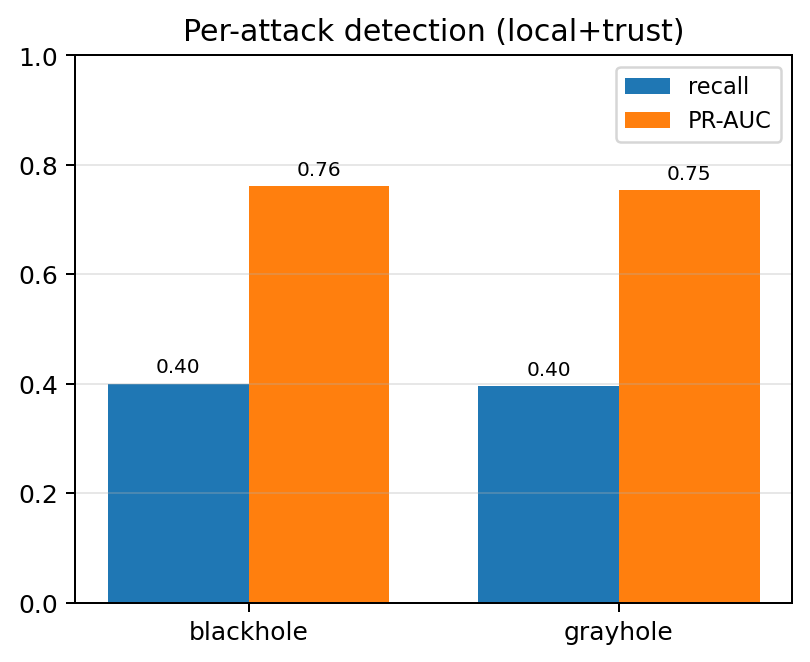

confusion_node.png


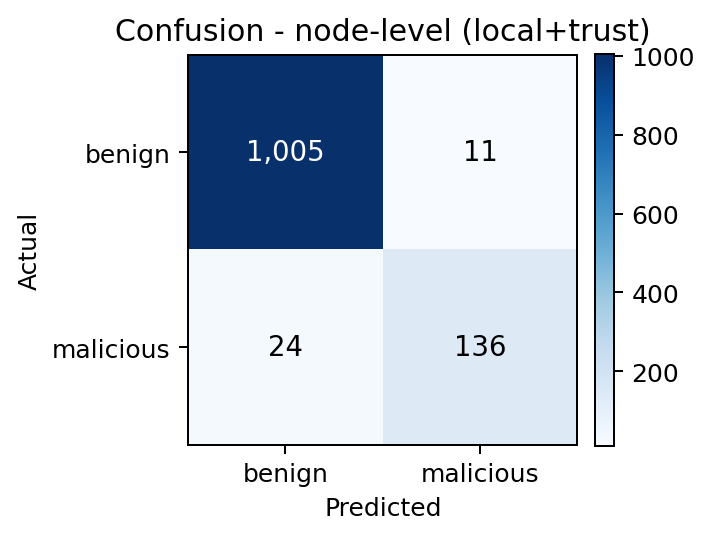

confusion_window.png


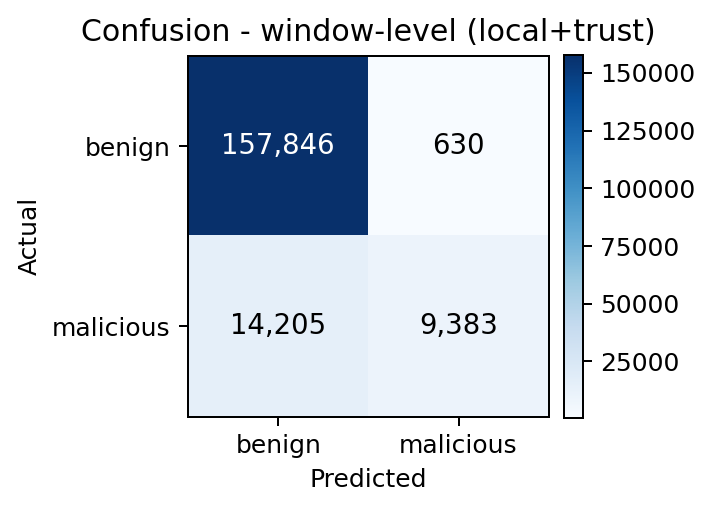

feature_importance.png


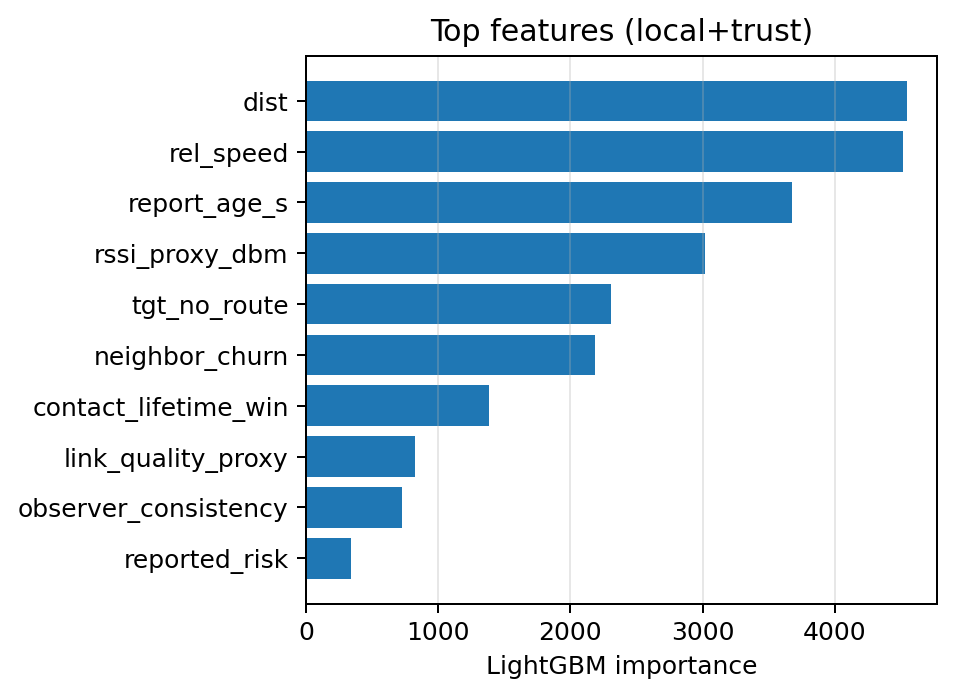

pr_curves.png


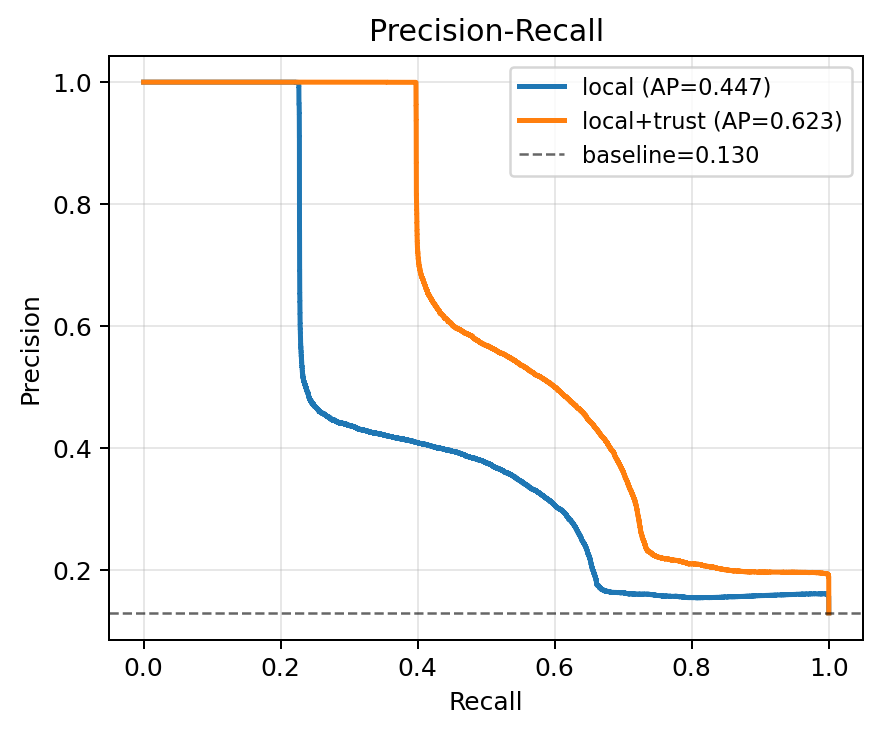

roc_curves.png


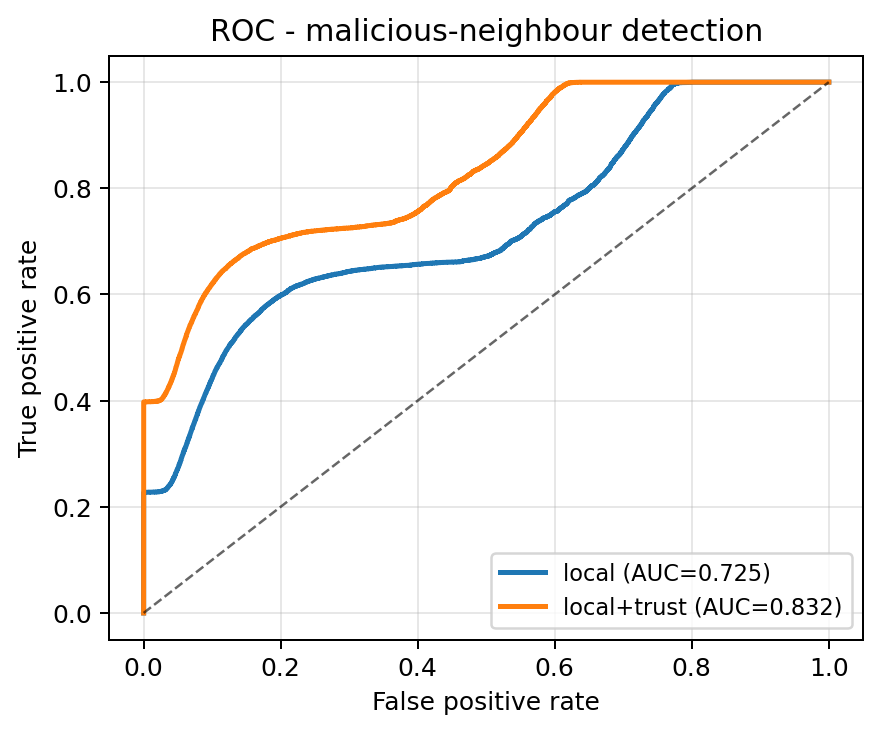

summary_table.png


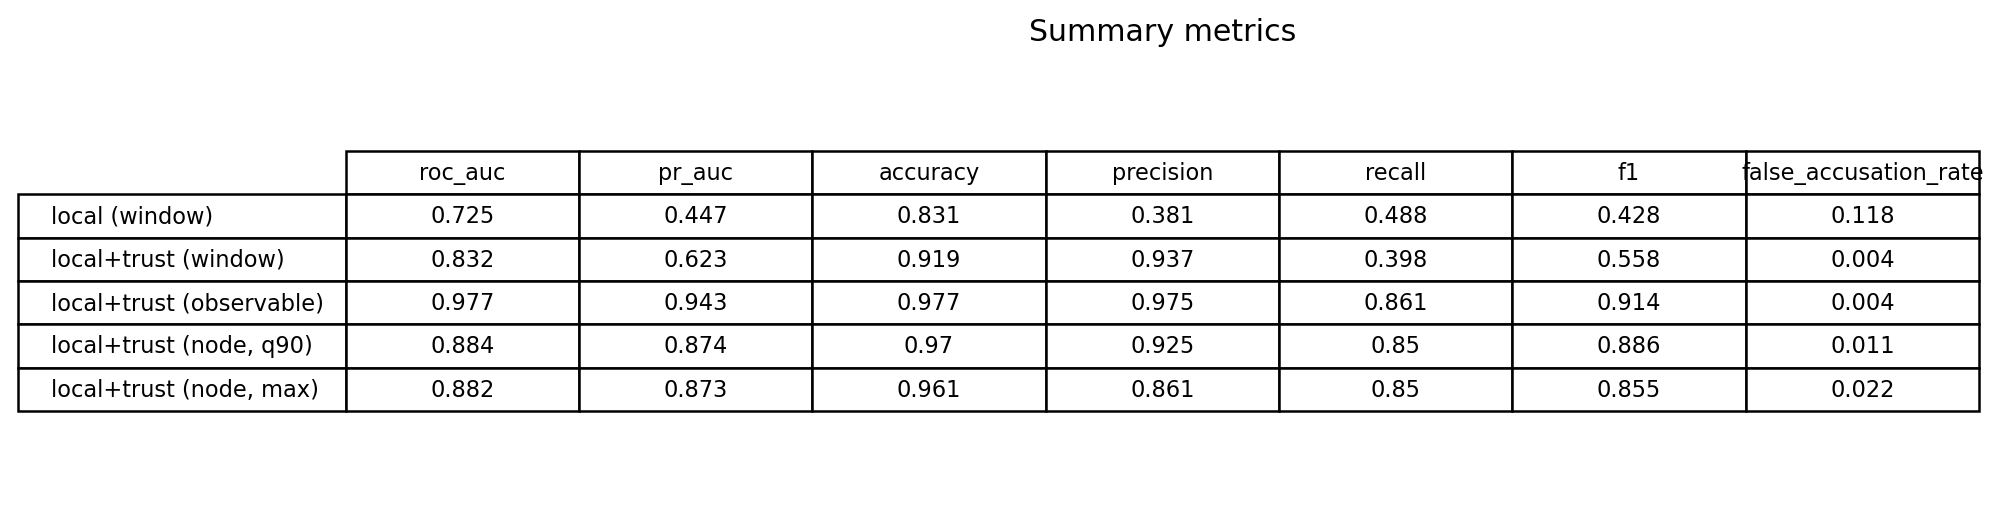

trust_iterative.png


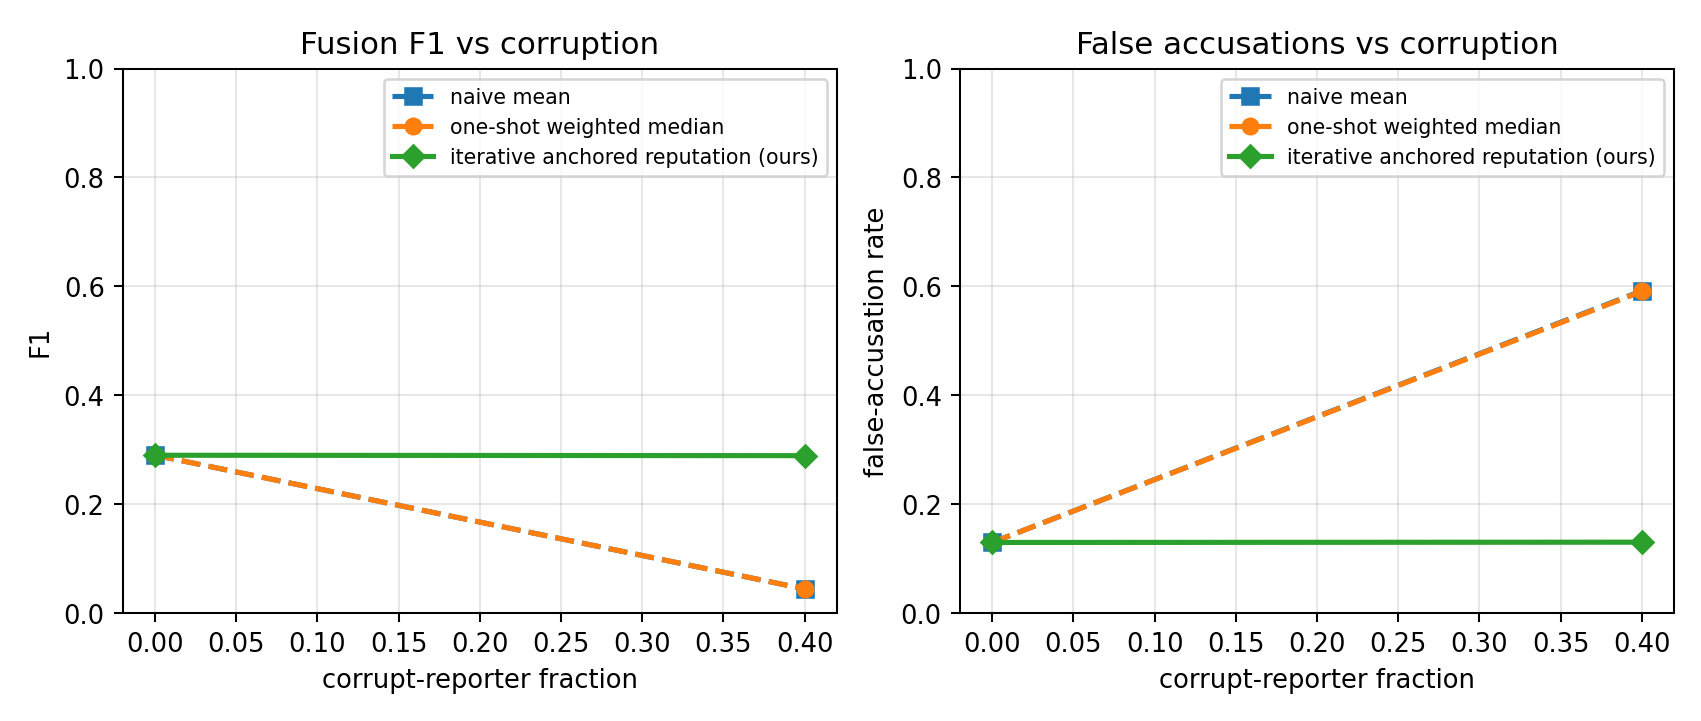

trust_robustness.png


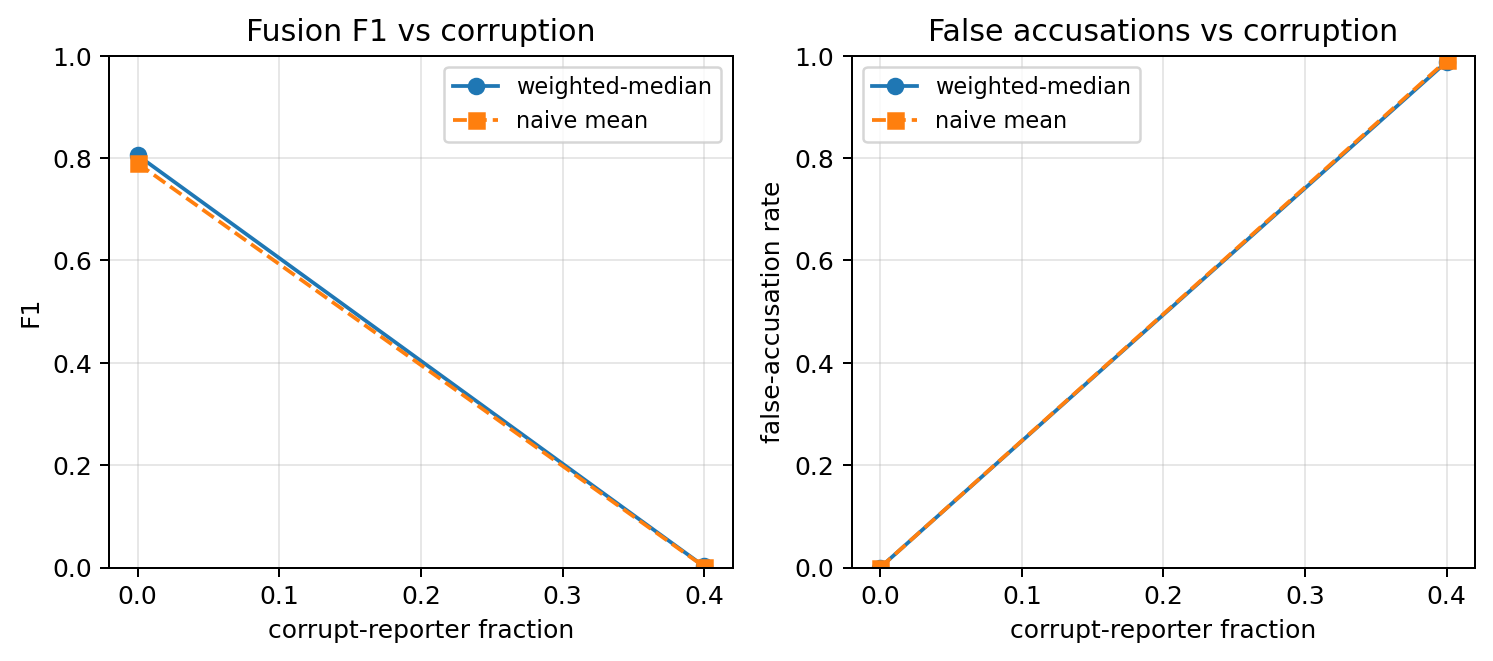

In [19]:
import glob, os
import pandas as pd
from IPython.display import Image, display
res = f"{OUT}/ids_results"
for name in ("summary_metrics","by_scenario_nodelevel","by_attack","by_corrupt","trust_fusion","trust_iterative"):
    for p in (f"{res}/tables/{name}.csv", f"{res}/tables/{name}.json"):
        if os.path.exists(p):
            print(f"\n=== {name} ===")
            try: display(pd.read_csv(p, index_col=0).round(3))
            except Exception: print(open(p).read()[:800])
figs = sorted(glob.glob(f"{res}/figures/*.png"))
print(f"\n{len(figs)} figures:")
for f in figs:
    print(os.path.basename(f)); display(Image(filename=f))


## 9. Peek + merge dataset to a single file

In [20]:
import glob, pandas as pd
parts = glob.glob(f"{SPLIT_DIR}/*.parquet") or glob.glob(f"{DS_DIR}/*.parquet")
df = pd.concat((pd.read_parquet(p) for p in parts), ignore_index=True)
print("rows:", len(df), "| columns:", len(df.columns))
merged = f"{OUT}/trust_manet_dataset.parquet"; df.to_parquet(merged, index=False); print("merged ->", merged)


rows: 182064 | columns: 38
merged -> /kaggle/working/trust_manet_dataset.parquet


## 10. Full matrix (450 runs) + updating the paper

Run the full factorial in chunks across sessions (resume skips finished runs), then rebuild,
split, train, and re-run the trust mechanism on `--which full`:
```python
!python scripts/run_matrix.py     --ns3-dir "$NS3_DIR" --which full --out "$RAW_DIR" --resume
!python scripts/build_dataset.py   --raw "$RAW_DIR" --out "$DS_DIR" --which full
!python scripts/split_dataset.py   --dataset "$DS_DIR" --out "$SPLIT_DIR" --mode config
!python scripts/train_ids.py       --dataset "$DS_DIR" --out "$OUT/ids_results"
!python scripts/trust_iterative.py --dataset "$DS_DIR" --out "$OUT/ids_results" --alpha 0.4 --gamma 4
```
The figures land in `ids_results/figures/` and the metric tables in `ids_results/tables/`.
To refresh the paper with the full-matrix numbers, send those `figures/` and
`tables/metrics.json` (+ `by_scenario_nodelevel.csv`) back and the .docx figures and
Results text will be swapped to match.

**Kaggle:** `/kaggle/temp` is wiped at session end — cache the build/raw as single `.tgz`
files under `/kaggle/working` and *Save Version*; use *Save & Run All* for long jobs.
**Colab:** outputs persist on Drive; `tar` the ns-3 build to skip rebuilds.
**Local:** everything stays under `./trust-manet-work/`.

## 11. Download everything (results + dataset) as one zip

Bundles `ids_results/` (figures, tables, metrics.json) and the dataset into a single zip and downloads it.

In [21]:
import os, shutil
from IPython.display import FileLink, display

# 1) bundle results + dataset into one folder
bundle = f"{OUT}/trust_manet_outputs"
if os.path.isdir(bundle): shutil.rmtree(bundle)
os.makedirs(bundle, exist_ok=True)

if os.path.isdir(f"{OUT}/ids_results"):
    shutil.copytree(f"{OUT}/ids_results", f"{bundle}/ids_results", dirs_exist_ok=True)

merged = f"{OUT}/trust_manet_dataset.parquet"
if os.path.exists(merged):
    shutil.copy(merged, bundle)                       # single merged dataset file
elif os.path.isdir(SPLIT_DIR):
    shutil.copytree(SPLIT_DIR, f"{bundle}/dataset_split", dirs_exist_ok=True)
elif os.path.isdir(DS_DIR):
    shutil.copytree(DS_DIR, f"{bundle}/dataset", dirs_exist_ok=True)

# 2) zip it
zip_base = f"{OUT}/trust_manet_outputs"
if os.path.exists(zip_base + ".zip"): os.remove(zip_base + ".zip")
shutil.make_archive(zip_base, "zip", bundle)
zip_path = zip_base + ".zip"
print(f"bundle ready: {zip_path}  ({os.path.getsize(zip_path)/1e6:.1f} MB)")

# 3) download depending on environment
if ENV == "colab":
    from google.colab import files
    files.download(zip_path)                           # browser download starts automatically
elif ENV == "kaggle":
    print("Kaggle: click the link below to download (also appears in the Output tab after Save Version):")
    rel = os.path.relpath(zip_path, "/kaggle/working")
    display(FileLink(rel))
else:
    print("Local: the zip is saved on disk at the path above.")


bundle ready: /kaggle/working/trust_manet_outputs.zip  (2.6 MB)
Kaggle: click the link below to download (also appears in the Output tab after Save Version):


/kaggle/working/trust-manet-dataset/trust_manet_outputs.zip

In [22]:
import os, shutil
from IPython.display import FileLink, display

# /kaggle/working ko ek zip mein daalo (zip khud /kaggle/working ke BAHAR banao
# taake woh khud ko recursively zip na kare)
zip_path = "/kaggle/kaggle_working.zip"
if os.path.exists(zip_path):
    os.remove(zip_path)
shutil.make_archive("/kaggle/kaggle_working", "zip", "/kaggle/working")

size_mb = os.path.getsize(zip_path) / 1e6
print(f"zip ready: {zip_path}  ({size_mb:.1f} MB)")

# zip ko working ke andar le aao taake download link + Output tab dono se mile
shutil.move(zip_path, "/kaggle/working/kaggle_working.zip")
print("download link:")
display(FileLink("kaggle_working.zip"))

zip ready: /kaggle/kaggle_working.zip  (16.3 MB)
download link:


/kaggle/working/trust-manet-dataset/kaggle_working.zip